# Ottawa EV Charging Usage Analysis

This notebook analyses cleaned electric-vehicle charging-session data from the City of Ottawa to identify demand trends, site and station utilization, typical charging behaviour, performance differences, and the potential for short-term demand forecasting.

## Core Business Questions

1. **How is EV charging demand changing over time?**
2. **Which sites and stations are the busiest, and which appear underutilized?**
3. **What does a typical charging session look like in terms of duration and energy delivered?**
4. **What factors appear to explain differences in performance across sites and stations?**
5. **Can historical charging-session data be used to forecast near-term charging demand?**

**Optional extension:** Estimate charging revenue using historical City of Ottawa charging rates.


## 1. Setup

Import the libraries used for data manipulation, visualization, geospatial analysis, and mapping. A global Matplotlib figure size is set so that charts remain wide and readable throughout the analysis.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
import geopandas as gpd
import pandas as pd
from pyproj import Transformer

plt.rcParams["figure.figsize"] = (20, 7)

import requests

## 2. Load the Cleaned Dataset

The analysis begins from the Parquet file produced in the cleaning notebook. Parquet is used because it preserves analytical data types such as datetimes more reliably than CSV.


In [3]:
# Load cleaned dataset
df = pd.read_parquet("ev_charging_usage_cleaned.parquet")

# Verify
print(df.shape)
df.head()

(22449, 20)


,transaction_id,session_id,charging_time,province_or_state,owner,site,address,point_x,point_y,station,card_number,end_reason,total_kwh,session_start,session_end,duration_hours,start_hour,day_of_week,month_year,address_clean
0,8971546,ce499016-c0fe-4b76-9224-e8e9e8b1caa3,0:33:48,ON,City of Ottawa,City of Ottawa - 190 Richmond Road,190 Richmond Rd.,-75.7475,45.39466,AAA-14533,1.10E+12,Charging ended by vehicle,4.06440,2022-05-01 11:36:44,2022-05-01 12:10:32,0.563333,11,Sunday,2022-05,190 Richmond Rd
1,8971910,daeaa8b8-2528-4b2a-a1ea-4aab820f188f,0:50:07,ON,City of Ottawa,City of Ottawa - 245 Crichton St.,245 Crichton St.,-75.6823,45.43930,AAA-14506,1.10E+12,The charging cable was disconnected and put ba...,2.92454,2022-05-01 12:07:03,2022-05-01 12:57:10,0.835278,12,Sunday,2022-05,245 Crichton St
2,8972766,5e4d5163-2c67-4049-ac1d-41193e6064d9,2:57:01,ON,City of Ottawa,City of Ottawa - 186 Main St.,186 Main St.,-75.6782,45.40886,AAA-14503,RC01086626836246,Charging ended by vehicle,20.59820,2022-05-01 11:43:33,2022-05-01 14:40:34,2.950278,11,Sunday,2022-05,186 Main St
3,8972887,c83802a2-1f6d-4c24-bba2-5bff14371aec,1:36:12,ON,City of Ottawa,City of Ottawa - 301 Laurier Avenue,301 Laurier Ave. E,-75.6793,45.42710,AAA-14508,MA01090921821958,The charging cable was disconnected and put ba...,11.52725,2022-05-01 13:21:37,2022-05-01 14:57:49,1.603333,13,Sunday,2022-05,301 Laurier Ave E
4,8973165,24715a5e-ccee-420f-ac17-0414a5ec14aa,0:34:59,ON,City of Ottawa,City of Ottawa - 2nd Avenue Parking Garage,170 Second Ave.,-75.6893,45.40323,AAB-20483,RC01086626807904,The charging cable was disconnected and put ba...,3.17881,2022-05-01 15:00:19,2022-05-01 15:35:18,0.583056,15,Sunday,2022-05,170 Second Ave


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22449 entries, 0 to 22448
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   transaction_id     22449 non-null  int64         
 1   session_id         22449 non-null  object        
 2   charging_time      22449 non-null  object        
 3   province_or_state  22449 non-null  object        
 4   owner              22449 non-null  object        
 5   site               22449 non-null  object        
 6   address            22449 non-null  object        
 7   point_x            22449 non-null  float64       
 8   point_y            22449 non-null  float64       
 9   station            22449 non-null  object        
 10  card_number        22449 non-null  object        
 11  end_reason         22449 non-null  object        
 12  total_kwh          22449 non-null  float64       
 13  session_start      22449 non-null  datetime64[ns]
 14  sessio

# Q1. How is EV charging demand changing over time?

This section examines the evolution of charging demand using both **session counts** and **energy delivered (kWh)**. The analysis moves from overall monthly trends to annual growth and then to seasonal patterns.


# Analysis

## Data Coverage

Before interpreting annual trends, it is important to confirm the time coverage of the dataset.

The dataset does not contain complete calendar-year coverage for every year. In particular, 2021 and 2024 are partial years, so their annual totals should not be compared directly with the complete 2022 and 2023 totals without qualification.

In [5]:
# Check dataset coverage by year
year_coverage = (
    df.groupby(df["session_start"].dt.year)["session_start"]
    .agg(["min", "max", "count"])
)

year_coverage

,min,max,count
session_start,,,
2021,2021-12-31 18:21:10,2021-12-31 18:21:10,1
2022,2022-01-01 18:00:51,2022-12-31 23:23:24,5395
2023,2023-01-01 09:43:35,2023-12-31 23:37:12,10118
2024,2024-01-01 01:08:38,2024-06-30 22:05:45,6935


### Coverage note

The dataset includes partial-year coverage for **2021** and **2024**. As a result, annual totals for those years should be interpreted as incomplete.

Where a fair year-over-year comparison is required, the analysis uses the two complete calendar years: **2022 and 2023**.


## Q1.1 Monthly Demand Trend

Monthly demand is measured in two complementary ways:

- **Number of charging sessions** — a measure of charging activity.
- **Total energy delivered (kWh)** — a measure of electricity demand.

Viewing both helps distinguish growth in the number of charging events from growth in the amount of energy consumed.


In [6]:
# Aggregate charging demand by month
monthly_demand = (
    df.groupby("month_year")
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum")
    )
    .reset_index()
)

monthly_demand.head()

,month_year,sessions,total_kwh
0,2021-12,1,2.55168
1,2022-01,69,998.41959
2,2022-02,56,946.19666
3,2022-03,132,1406.97182
4,2022-04,340,3667.49530


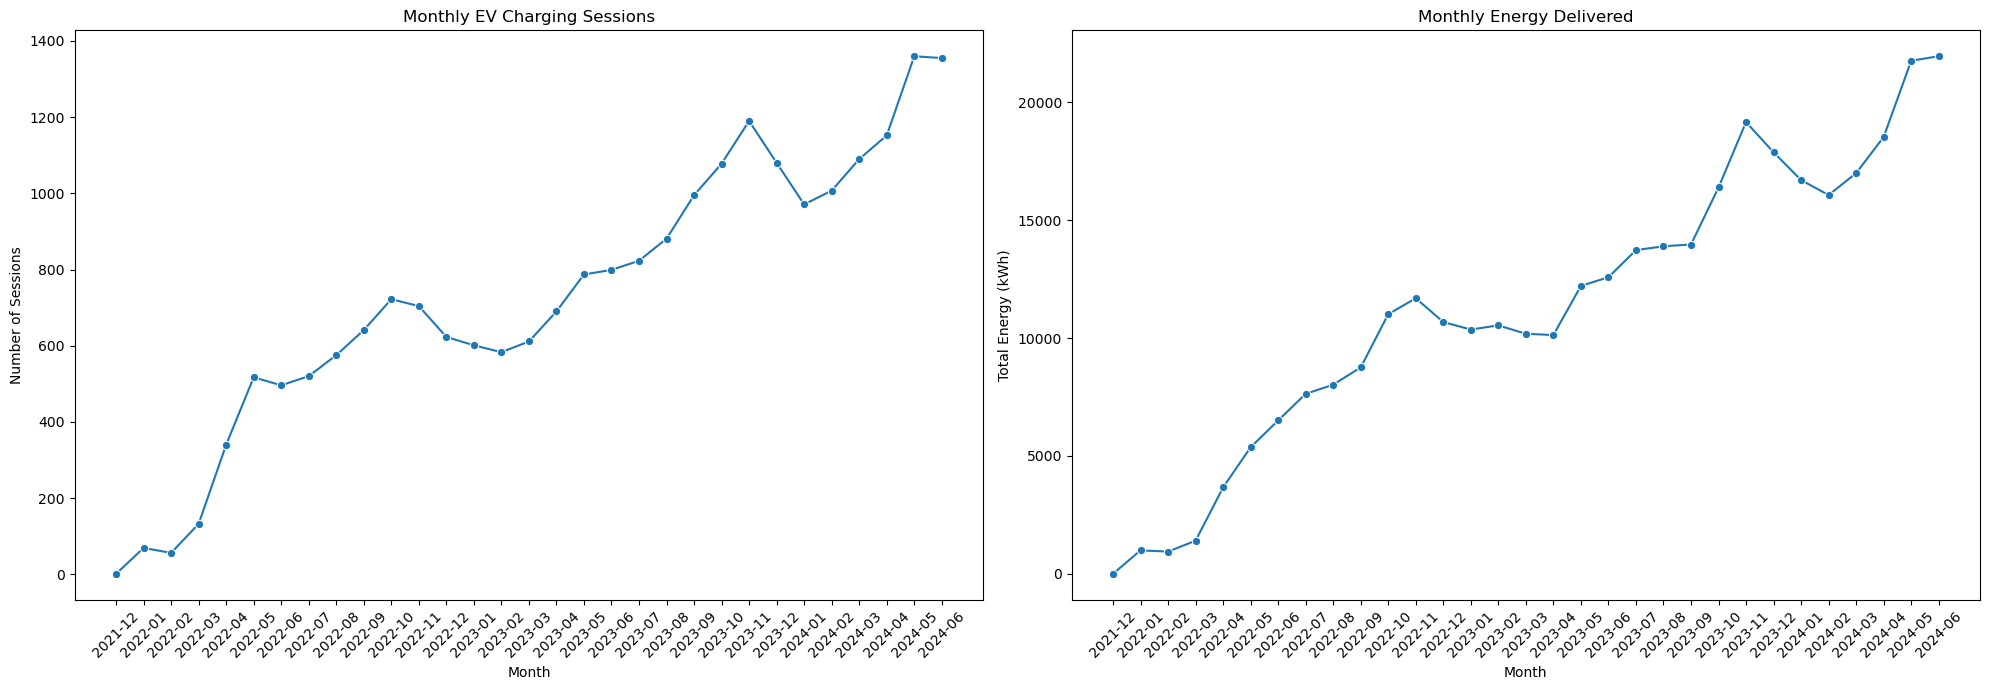

In [7]:
# Create side-by-side monthly demand charts
fig, axes = plt.subplots(1, 2)
monthly_demand["month_year"] = monthly_demand["month_year"].astype(str)
# Monthly charging sessions
sns.lineplot(
    data=monthly_demand,
    x="month_year",
    y="sessions",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Monthly EV Charging Sessions")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Sessions")
axes[0].tick_params(axis="x", rotation=45)

# Monthly energy delivered
sns.lineplot(
    data=monthly_demand,
    x="month_year",
    y="total_kwh",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Monthly Energy Delivered")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total Energy (kWh)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Monthly trend insight

EV charging demand increased substantially across the study period. Both monthly charging sessions and total energy delivered show a strong upward trajectory despite several short-term fluctuations.

By spring 2024, monthly charging activity had reached the highest levels observed in the dataset.


## Q1.2 Annual Demand Trajectory

Annual totals provide a higher-level view of how charging activity and energy demand changed from year to year.

Because 2021 and 2024 are partial years, the annual chart is primarily used to show the overall trajectory rather than to make direct like-for-like comparisons across all four years.


In [8]:
# Create annual totals from the session start date
annual_demand = (
    df.assign(year=df["session_start"].dt.year)
    .groupby("year")
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum")
    )
    .reset_index()
)

annual_demand

,year,sessions,total_kwh
0,2021,1,2.55168
1,2022,5395,76690.19693
2,2023,10118,161009.83551
3,2024,6935,111995.21154


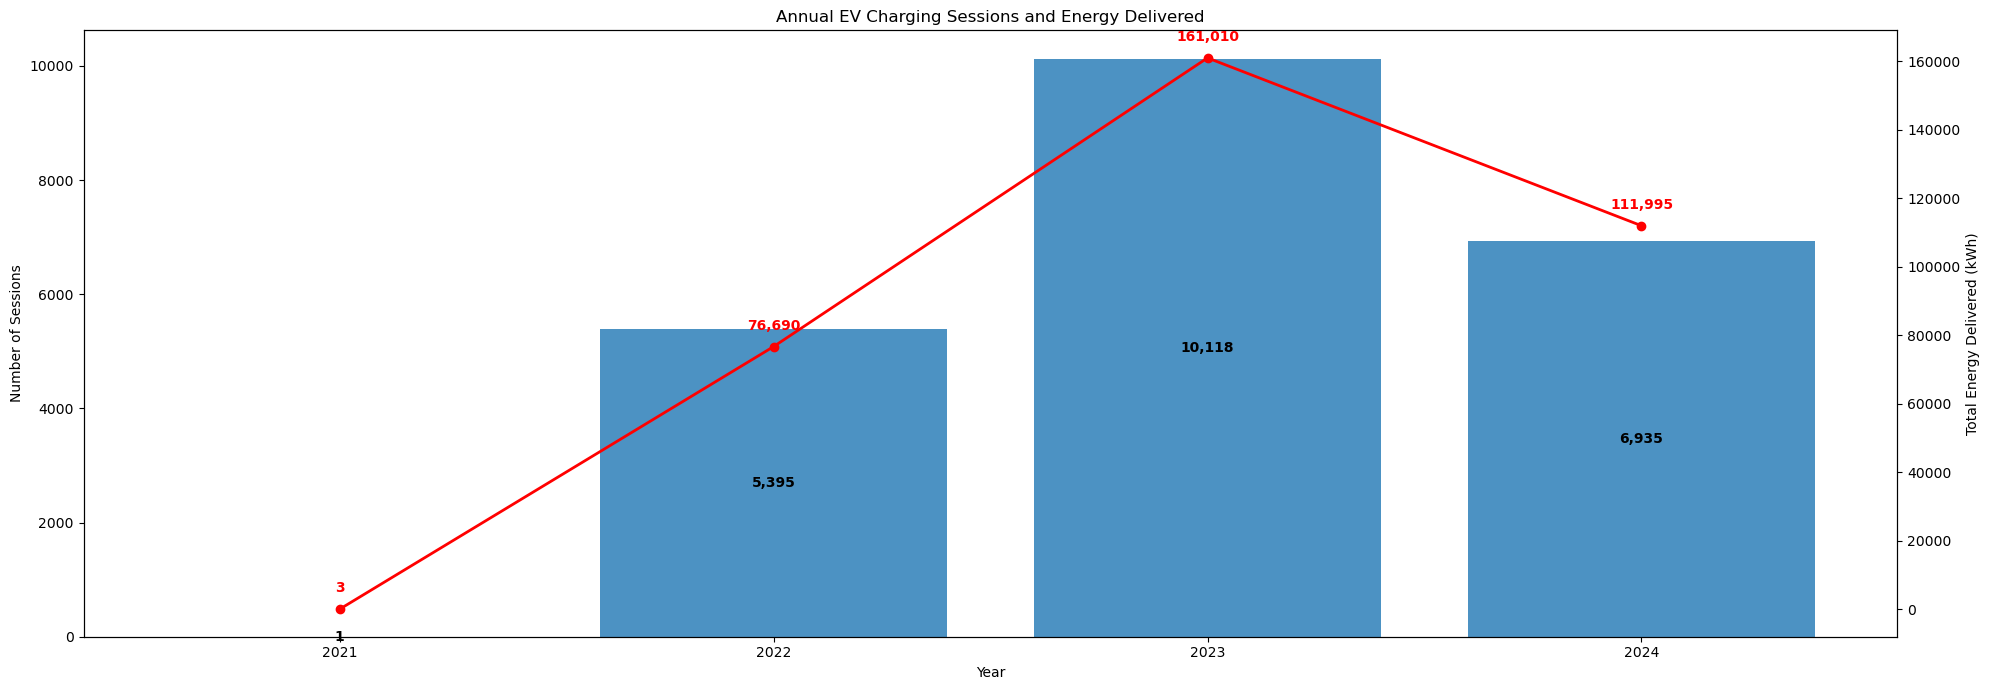

In [9]:
# Create a bar + line combo chart for annual demand
fig, ax1 = plt.subplots()

# Bar chart for annual charging sessions
bars = ax1.bar(
    annual_demand["year"].astype(str),
    annual_demand["sessions"],
    alpha=0.8
)

ax1.set_title("Annual EV Charging Sessions and Energy Delivered")
ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Sessions")

# Add session-count labels inside the bars
for bar in bars:
    height = bar.get_height()

    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,
        f"{int(height):,}",
        ha="center",
        va="center",
        fontweight="bold"
    )

# Create second y-axis for energy delivered
ax2 = ax1.twinx()

# Line chart for annual energy delivered
ax2.plot(
    annual_demand["year"].astype(str),
    annual_demand["total_kwh"],
    marker="o",
    linewidth=2,
    color="red"
)

ax2.set_ylabel("Total Energy Delivered (kWh)")

# Add energy labels above line markers
for x, y in zip(
    annual_demand["year"].astype(str),
    annual_demand["total_kwh"]
):
    ax2.annotate(
        f"{y:,.0f}",
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color="red",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## Q1.3 Full-Year Growth: 2022 vs 2023

To quantify annual growth fairly, only the two complete calendar years are compared.

This calculation measures the percentage change in:

- charging-session volume, and
- total energy delivered.


In [10]:
# Compare complete calendar years only
full_years = annual_demand[
    annual_demand["year"].isin([2022, 2023])
].copy()

# Calculate year-over-year percentage growth
session_growth = (
    (full_years.loc[full_years["year"] == 2023, "sessions"].iloc[0]
     / full_years.loc[full_years["year"] == 2022, "sessions"].iloc[0])
    - 1
) * 100

energy_growth = (
    (full_years.loc[full_years["year"] == 2023, "total_kwh"].iloc[0]
     / full_years.loc[full_years["year"] == 2022, "total_kwh"].iloc[0])
    - 1
) * 100

print(f"Session growth (2022 → 2023): {session_growth:.1f}%")
print(f"Energy growth (2022 → 2023): {energy_growth:.1f}%")

Session growth (2022 → 2023): 87.5%
Energy growth (2022 → 2023): 109.9%


## Q1.4 Seasonal Demand Pattern

Seasonality is evaluated using only **2022 and 2023**, avoiding the incomplete 2021 and 2024 periods.

This allows month-of-year demand to be compared on a consistent basis without overstating January–June demand simply because those months contain an extra partial year of data.


In [11]:
# Use only complete calendar years for seasonality analysis
season_df = df[
    df["session_start"].dt.year.isin([2022, 2023])
].copy()

# Create month fields
season_df["month_num"] = season_df["session_start"].dt.month
season_df["month_name"] = season_df["session_start"].dt.month_name()

# Aggregate demand by month
seasonal_demand = (
    season_df.groupby(["month_num", "month_name"])
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum")
    )
    .reset_index()
    .sort_values("month_num")
)

seasonal_demand

,month_num,month_name,sessions,total_kwh
0,1,January,670,11359.70066
1,2,February,639,11484.87977
2,3,March,743,11589.69484
3,4,April,1030,13794.75262
4,5,May,1304,17580.78458
5,6,June,1295,19085.69103
6,7,July,1343,21362.05907
7,8,August,1456,21916.82413
8,9,September,1636,22722.38432
9,10,October,1800,27397.30723


### Average month-of-year demand

The monthly totals for 2022 and 2023 are first calculated separately and then averaged by calendar month. This produces a cleaner view of recurring seasonal behaviour.


In [12]:
# First aggregate by year and month
monthly_seasonality = (
    season_df.assign(year=season_df["session_start"].dt.year)
    .groupby(["year", "month_num", "month_name"])
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum")
    )
    .reset_index()
)

# Average each calendar month across 2022 and 2023
seasonal_avg = (
    monthly_seasonality.groupby(["month_num", "month_name"])
    .agg(
        avg_sessions=("sessions", "mean"),
        avg_kwh=("total_kwh", "mean")
    )
    .reset_index()
    .sort_values("month_num")
)

seasonal_avg

,month_num,month_name,avg_sessions,avg_kwh
0,1,January,335.0,5679.850330
1,2,February,319.5,5742.439885
2,3,March,371.5,5794.847420
3,4,April,515.0,6897.376310
4,5,May,652.0,8790.392290
5,6,June,647.5,9542.845515
6,7,July,671.5,10681.029535
7,8,August,728.0,10958.412065
8,9,September,818.0,11361.192160
9,10,October,900.0,13698.653615


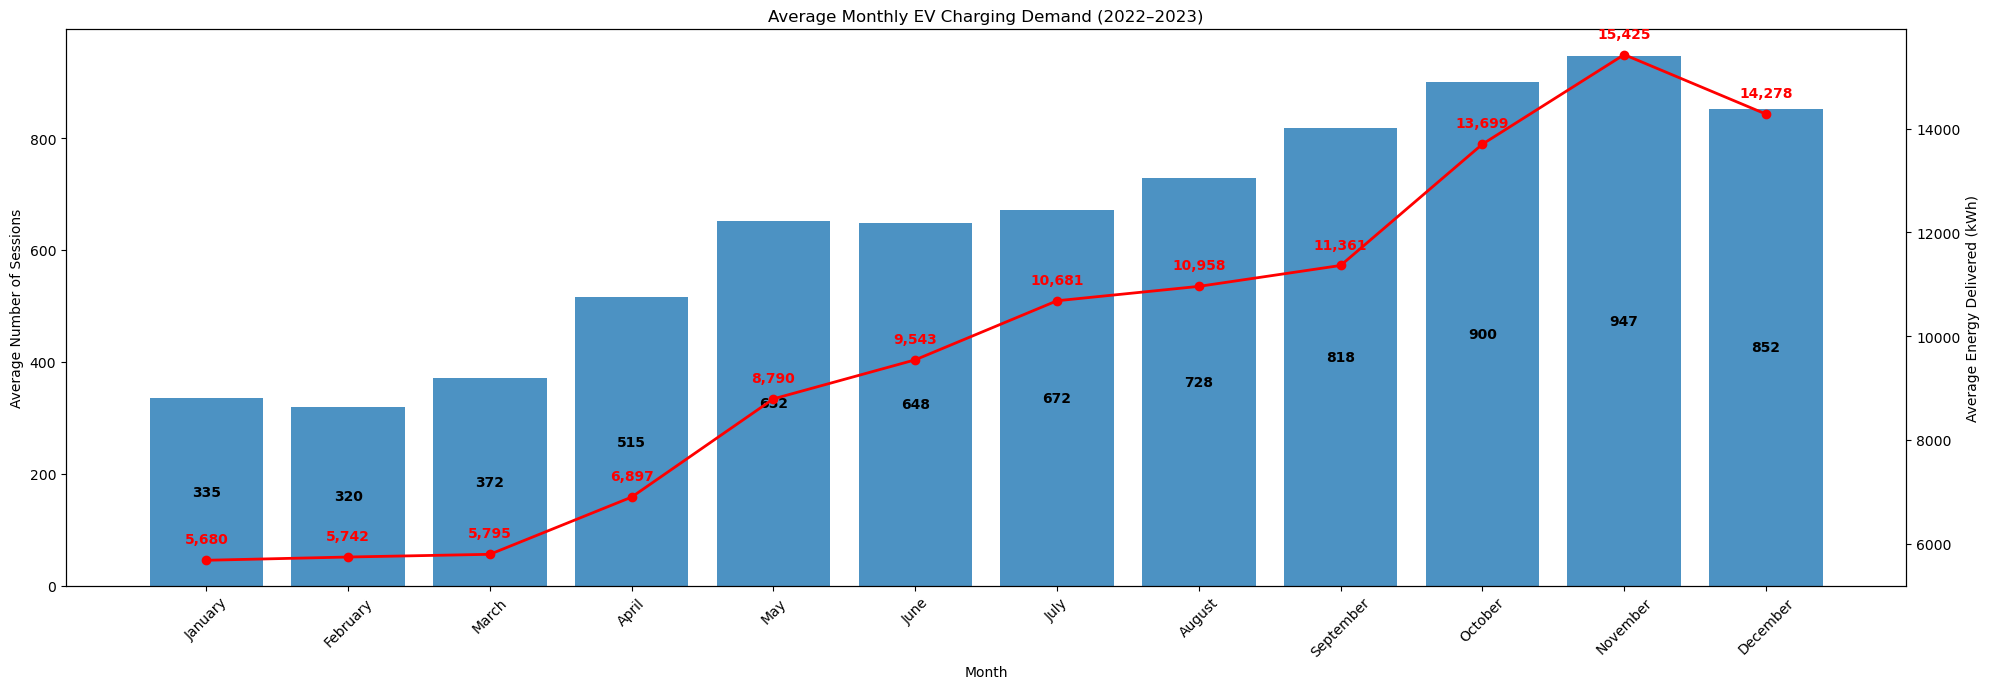

In [13]:
# Create seasonal demand combo chart
fig, ax1 = plt.subplots()

# Bar chart for average monthly sessions
bars = ax1.bar(
    seasonal_avg["month_name"],
    seasonal_avg["avg_sessions"],
    alpha=0.8
)

ax1.set_title("Average Monthly EV Charging Demand (2022–2023)")
ax1.set_xlabel("Month")
ax1.set_ylabel("Average Number of Sessions")
ax1.tick_params(axis="x", rotation=45)

# Add session-count labels inside the bars
for bar in bars:
    height = bar.get_height()

    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,
        f"{height:,.0f}",
        ha="center",
        va="center",
        fontweight="bold"
    )

# Create second y-axis for average energy delivered
ax2 = ax1.twinx()

ax2.plot(
    seasonal_avg["month_name"],
    seasonal_avg["avg_kwh"],
    marker="o",
    linewidth=2,
    color="red"
)

ax2.set_ylabel("Average Energy Delivered (kWh)")

# Add labels to line markers
for x, y in zip(
    seasonal_avg["month_name"],
    seasonal_avg["avg_kwh"]
):
    ax2.annotate(
        f"{y:,.0f}",
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color="red",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Seasonal insight

Charging demand generally rises through the year and is strongest in late fall, with both average session counts and average energy delivered peaking around November before easing in December.

A plausible contributing factor is colder weather: EV battery efficiency and driving range typically decline in low temperatures, which may increase charging frequency and energy demand. This is a **possible explanation**, not a causal conclusion from this dataset alone.


## Q1 Conclusion

The evidence indicates that Ottawa's EV charging demand is increasing over time.

- Monthly sessions and total kWh both trend upward across the study period.
- The complete-year comparison between 2022 and 2023 shows substantial growth.
- Demand also displays a seasonal pattern, with stronger usage toward late fall and early winter.
- Partial-year coverage in 2021 and 2024 is kept separate from full-year growth comparisons.

Together, these results answer the first business question and establish the broader demand context for the site- and station-level analysis that follows.


---

# Q2. Which sites and stations are the busiest, and which appear underutilized?

This section will evaluate utilization at both the **site** and **individual station** levels.

### Planned measures
- Number of charging sessions
- Total energy delivered (kWh)
- Average energy delivered per session
- Average session duration
- Share of total network demand
- Highest- and lowest-utilization sites/stations

### Supporting analysis
Where useful, usage patterns by **day of week** and **hour of day** can be compared across high- and low-utilization locations.

The goal is to distinguish genuinely busy locations from stations that may be underused relative to the rest of the network.


In [14]:
# Create one site-level summary table
site_usage = (
    df.groupby("site")
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum"),
        avg_duration_hours=("duration_hours", "mean"),
        total_hours=("duration_hours", "sum")
    )
    .reset_index()
)

# Sort from busiest site to least busy site
site_usage = site_usage.sort_values(
    by="sessions",
    ascending=False
)

site_usage

,site,sessions,total_kwh,avg_duration_hours,total_hours
2,City of Ottawa - 118 Cartier St.,2546,40702.58792,2.860178,7282.012222
0,City Hall - Ottawa,2507,25228.29039,1.855507,4651.755000
11,City of Ottawa - 301 Laurier Avenue,2068,32687.79148,2.980456,6163.583611
3,City of Ottawa - 122 Daly Ave.,1868,34562.97277,3.432877,6412.614444
15,City of Ottawa - 6 Oak St.,1573,26014.46440,2.826546,4446.156667
6,City of Ottawa - 186 Main St.,1546,21281.65754,2.356423,3643.029444
7,City of Ottawa - 190 Richmond Road,1511,21496.55318,2.428709,3669.779444
10,City of Ottawa - 2nd Avenue Parking Garage,1511,13652.05539,1.859733,2810.055833
16,City of Ottawa - 930 Wellington Street,1479,28968.38482,3.514295,5197.642778
8,City of Ottawa - 245 Crichton St.,1165,18425.61202,2.817916,3282.871667


### Site-level usage interpretation

The site summary combines several measures rather than relying on session count alone. This is important because a site can have fewer sessions but still deliver substantial energy or accumulate many connected hours.

For example, **Chapel Hill Park N Ride** has fewer sessions than many downtown sites but relatively high total energy and connected hours, suggesting a different usage pattern rather than simply low demand.


In [15]:
# Show the 10 busiest sites by number of sessions
top_10_sites = site_usage.head(10)

top_10_sites

,site,sessions,total_kwh,avg_duration_hours,total_hours
2,City of Ottawa - 118 Cartier St.,2546,40702.58792,2.860178,7282.012222
0,City Hall - Ottawa,2507,25228.29039,1.855507,4651.755000
11,City of Ottawa - 301 Laurier Avenue,2068,32687.79148,2.980456,6163.583611
3,City of Ottawa - 122 Daly Ave.,1868,34562.97277,3.432877,6412.614444
15,City of Ottawa - 6 Oak St.,1573,26014.46440,2.826546,4446.156667
6,City of Ottawa - 186 Main St.,1546,21281.65754,2.356423,3643.029444
7,City of Ottawa - 190 Richmond Road,1511,21496.55318,2.428709,3669.779444
10,City of Ottawa - 2nd Avenue Parking Garage,1511,13652.05539,1.859733,2810.055833
16,City of Ottawa - 930 Wellington Street,1479,28968.38482,3.514295,5197.642778
8,City of Ottawa - 245 Crichton St.,1165,18425.61202,2.817916,3282.871667


In [16]:
import plotly.express as px

# Select the top 10 busiest sites by number of sessions
top_10_sites = site_usage.head(10).copy()

# Sort so the busiest site appears at the top
top_10_sites = top_10_sites.sort_values("sessions", ascending=True)

# Create the interactive horizontal bar chart
fig = px.bar(
    top_10_sites,
    x="sessions",
    y="site",
    orientation="h",
    title="Top 10 Busiest EV Charging Sites by Number of Sessions",
    custom_data=["total_kwh", "avg_duration_hours"]
)

# Customize hover text
fig.update_traces(
    hovertemplate=
    "<b>%{y}</b><br>" +
    "Sessions: %{x:,}<br>" +
    "Total Energy: %{customdata[0]:,.2f} kWh<br>" +
    "Avg Duration: %{customdata[1]:.2f} hours<br>" +
    "<extra></extra>"
)

# Update layout
fig.update_layout(
    xaxis_title="Number of Sessions",
    yaxis_title="Site"
)

fig.show()

In [17]:
# Select the top 10 sites by total energy delivered
top_10_energy_sites = (
    site_usage
    .sort_values("total_kwh", ascending=False)
    .head(10)
    .copy()
)

# Sort so the highest-energy site appears at the top
top_10_energy_sites = top_10_energy_sites.sort_values(
    "total_kwh",
    ascending=True
)

# Create the interactive horizontal bar chart
fig = px.bar(
    top_10_energy_sites,
    x="total_kwh",
    y="site",
    orientation="h",
    title="Top 10 EV Charging Sites by Total Energy Delivered",
    custom_data=["sessions", "avg_duration_hours"]
)

# Customize hover information
fig.update_traces(
    hovertemplate=
    "<b>%{y}</b><br>" +
    "Total Energy: %{x:,.2f} kWh<br>" +
    "Sessions: %{customdata[0]:,}<br>" +
    "Avg Duration: %{customdata[1]:.2f} hours<br>" +
    "<extra></extra>"
)

# Update axis labels
fig.update_layout(
    xaxis_title="Total Energy Delivered (kWh)",
    yaxis_title="Site"
)

fig.show()

In [18]:
# Sort sites from lowest to highest number of sessions
low_usage_sites = site_usage.sort_values(
    by="sessions",
    ascending=True
)

# Display the 10 sites with the fewest charging sessions
low_usage_sites.head(10)

,site,sessions,total_kwh,avg_duration_hours,total_hours
12,City of Ottawa - 33 Quill St.,8,237.77938,5.137083,41.096667
13,City of Ottawa - 40 Cobourg St - North,112,1540.38908,3.143750,352.100000
14,City of Ottawa - 40 Cobourg St - South,191,2471.70871,2.993720,571.800556
9,City of Ottawa - 283 Cyr Ave.,421,4582.51674,2.384685,1003.952500
4,City of Ottawa - 1551 Lycée Place,585,8949.18206,2.630706,1538.963056
18,City of Ottawa - Chapel Hill Park N Ride,725,25019.04686,7.377611,5348.767778
17,City of Ottawa - Blackburn Arena,739,11696.05548,2.950460,2180.390278
5,City of Ottawa - 170 Primrose Ave.,935,17743.25135,3.246587,3035.558611
1,City of Ottawa - 113 Beechwood Ave.,959,14437.49609,2.758792,2645.681389
8,City of Ottawa - 245 Crichton St.,1165,18425.61202,2.817916,3282.871667


In [19]:
# Rank each site by usage measures
# Lower rank number = lower observed usage

site_usage["session_rank"] = site_usage["sessions"].rank(
    ascending=True
)

site_usage["energy_rank"] = site_usage["total_kwh"].rank(
    ascending=True
)

site_usage["hours_rank"] = site_usage["total_hours"].rank(
    ascending=True
)

# Calculate the average rank across the three measures
site_usage["avg_usage_rank"] = (
    site_usage[
        [
            "session_rank",
            "energy_rank",
            "hours_rank"
        ]
    ]
    .mean(axis=1)
)

# Sort from lowest observed usage to highest
site_usage.sort_values(
    "avg_usage_rank"
)[
    [
        "site",
        "sessions",
        "total_kwh",
        "total_hours",
        "avg_usage_rank"
    ]
].head(10)

,site,sessions,total_kwh,total_hours,avg_usage_rank
12,City of Ottawa - 33 Quill St.,8,237.77938,41.096667,1.000000
13,City of Ottawa - 40 Cobourg St - North,112,1540.38908,352.100000,2.000000
14,City of Ottawa - 40 Cobourg St - South,191,2471.70871,571.800556,3.000000
9,City of Ottawa - 283 Cyr Ave.,421,4582.51674,1003.952500,4.000000
4,City of Ottawa - 1551 Lycée Place,585,8949.18206,1538.963056,5.000000
17,City of Ottawa - Blackburn Arena,739,11696.05548,2180.390278,6.333333
1,City of Ottawa - 113 Beechwood Ave.,959,14437.49609,2645.681389,8.000000
5,City of Ottawa - 170 Primrose Ave.,935,17743.25135,3035.558611,8.666667
10,City of Ottawa - 2nd Avenue Parking Garage,1511,13652.05539,2810.055833,9.166667
8,City of Ottawa - 245 Crichton St.,1165,18425.61202,3282.871667,10.000000


In [20]:
# Calculate median usage values across all sites
median_sessions = site_usage["sessions"].median()
median_kwh = site_usage["total_kwh"].median()
median_hours = site_usage["total_hours"].median()

print("Median Sessions:", median_sessions)
print("Median Total kWh:", median_kwh)
print("Median Total Hours:", median_hours)

Median Sessions: 1165.0
Median Total kWh: 18425.61202
Median Total Hours: 3282.8716666666664


In [21]:
# Identify sites below the median on all three usage measures
underused_sites = site_usage[
    (site_usage["sessions"] < median_sessions) &
    (site_usage["total_kwh"] < median_kwh) &
    (site_usage["total_hours"] < median_hours)
].copy()

# Sort from lowest to highest number of sessions
underused_sites = underused_sites.sort_values(
    "sessions",
    ascending=True
)

underused_sites

,site,sessions,total_kwh,avg_duration_hours,total_hours,session_rank,energy_rank,hours_rank,avg_usage_rank
12,City of Ottawa - 33 Quill St.,8,237.77938,5.137083,41.096667,1.0,1.0,1.0,1.000000
13,City of Ottawa - 40 Cobourg St - North,112,1540.38908,3.143750,352.100000,2.0,2.0,2.0,2.000000
14,City of Ottawa - 40 Cobourg St - South,191,2471.70871,2.993720,571.800556,3.0,3.0,3.0,3.000000
9,City of Ottawa - 283 Cyr Ave.,421,4582.51674,2.384685,1003.952500,4.0,4.0,4.0,4.000000
4,City of Ottawa - 1551 Lycée Place,585,8949.18206,2.630706,1538.963056,5.0,5.0,5.0,5.000000
17,City of Ottawa - Blackburn Arena,739,11696.05548,2.950460,2180.390278,7.0,6.0,6.0,6.333333
5,City of Ottawa - 170 Primrose Ave.,935,17743.25135,3.246587,3035.558611,8.0,9.0,9.0,8.666667
1,City of Ottawa - 113 Beechwood Ave.,959,14437.49609,2.758792,2645.681389,9.0,8.0,7.0,8.000000


In [22]:
# Calculate each site's usage as a percentage of the network median
underused_sites["sessions_pct_median"] = (
    underused_sites["sessions"] / median_sessions
) * 100

underused_sites["kwh_pct_median"] = (
    underused_sites["total_kwh"] / median_kwh
) * 100

underused_sites["hours_pct_median"] = (
    underused_sites["total_hours"] / median_hours
) * 100

In [23]:
# Reshape the data so Plotly can display the three measures together
underused_plot = underused_sites.melt(
    id_vars="site",
    value_vars=[
        "sessions_pct_median",
        "kwh_pct_median",
        "hours_pct_median"
    ],
    var_name="usage_measure",
    value_name="percent_of_median"
)

# Give the measures cleaner names for the chart
underused_plot["usage_measure"] = underused_plot["usage_measure"].replace({
    "sessions_pct_median": "Sessions",
    "kwh_pct_median": "Energy Delivered",
    "hours_pct_median": "Connected Hours"
})

In [24]:
# Create an interactive comparison chart
fig = px.bar(
    underused_plot,
    x="percent_of_median",
    y="site",
    color="usage_measure",
    orientation="h",
    barmode="group",
    title="Lower-Usage Sites Compared with the Network Median"
)

# Add a reference line showing the network median
fig.add_vline(
    x=100,
    line_dash="dash",
    annotation_text="Network Median",
    annotation_position="top"
)

# Update labels
fig.update_layout(
    xaxis_title="Usage as % of Network Median",
    yaxis_title="Site",
    legend_title="Usage Measure"
)

fig.show()

## Q2 Conclusion

Site usage varies substantially across the network.

The busiest locations are led by **118 Cartier St., City Hall, 301 Laurier Avenue, and 122 Daly Ave.** Lower observed usage is concentrated at sites such as **33 Quill St., 40 Cobourg St., and 283 Cyr Ave.**

A site is treated as lower-use only when it falls below the network median across multiple measures, including sessions, total energy, and total connected hours. This avoids labelling a site as underused based on a single measure.

**Important limitation:** the number of distinct station IDs observed in the usage dataset should not be interpreted as the site's true installed charging capacity. Actual port capacity is examined separately using the infrastructure datasets.


---

# Q3. What does a typical charging session look like in terms of duration and energy delivered?

This section will describe the behaviour of an individual charging session.

### Planned measures
- Mean and median session duration
- Mean and median energy delivered
- Distribution of `duration_hours`
- Distribution of `total_kwh`
- Quartiles and outliers
- Relationship between session duration and energy delivered

The emphasis will be on the **typical session**, while also identifying unusually long or energy-intensive sessions.


In [25]:
# Calculate key statistics for a typical charging session
session_summary = df[
    ["duration_hours", "total_kwh"]
].describe()

session_summary

,duration_hours,total_kwh
count,22449.000000,22449.000000
mean,2.863282,15.577433
std,2.882790,15.165249
min,0.000278,0.000000
25%,1.034444,4.873170
50%,1.997500,10.284920
75%,3.644444,21.654450
max,42.815000,121.781100


In [26]:
# Calculate mean and median session duration
mean_duration = df["duration_hours"].mean()
median_duration = df["duration_hours"].median()

# Calculate mean and median energy delivered
mean_kwh = df["total_kwh"].mean()
median_kwh = df["total_kwh"].median()

print(f"Mean Session Duration: {mean_duration:.2f} hours")
print(f"Median Session Duration: {median_duration:.2f} hours")

print(f"\nMean Energy Delivered: {mean_kwh:.2f} kWh")
print(f"Median Energy Delivered: {median_kwh:.2f} kWh")

Mean Session Duration: 2.86 hours
Median Session Duration: 2.00 hours

Mean Energy Delivered: 15.58 kWh
Median Energy Delivered: 10.28 kWh


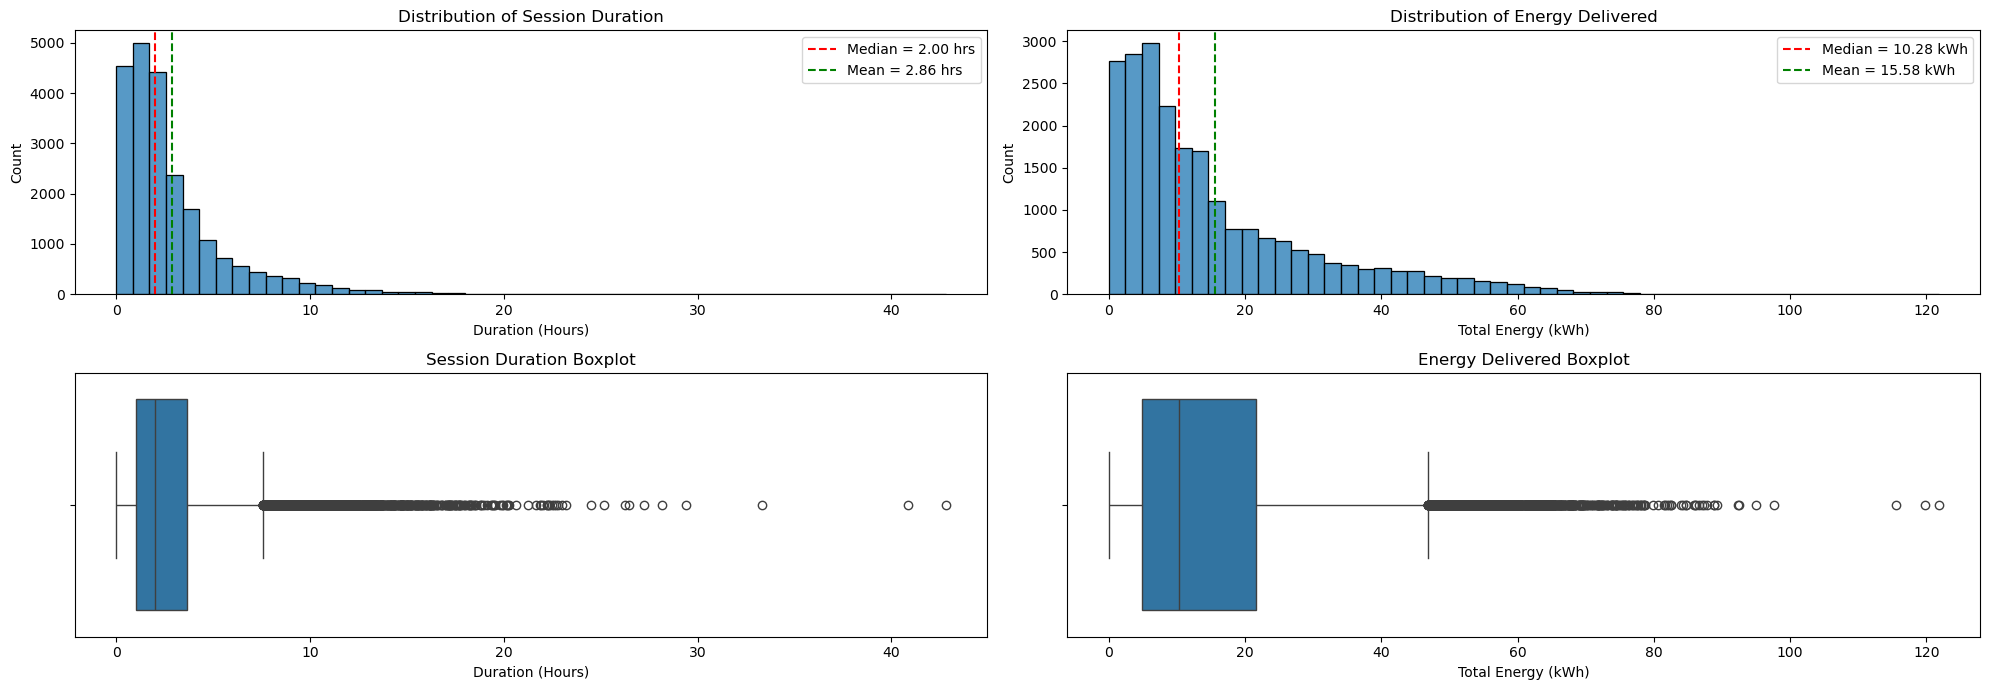

In [27]:
# Create a 2x2 figure
fig, axes = plt.subplots(2, 2)

# -----------------------------
# Top Left: Session Duration Histogram
# -----------------------------
sns.histplot(
    df["duration_hours"],
    bins=50,
    ax=axes[0, 0]
)

# Add median and mean lines
axes[0, 0].axvline(
    median_duration,
    color="red",
    linestyle="--",
    label=f"Median = {median_duration:.2f} hrs"
)

axes[0, 0].axvline(
    mean_duration,
    color="green",
    linestyle="--",
    label=f"Mean = {mean_duration:.2f} hrs"
)

axes[0, 0].set_title("Distribution of Session Duration")
axes[0, 0].set_xlabel("Duration (Hours)")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()


# -----------------------------
# Top Right: Energy Histogram
# -----------------------------
sns.histplot(
    df["total_kwh"],
    bins=50,
    ax=axes[0, 1]
)

# Add median and mean lines
axes[0, 1].axvline(
    median_kwh,
    color="red",
    linestyle="--",
    label=f"Median = {median_kwh:.2f} kWh"
)

axes[0, 1].axvline(
    mean_kwh,
    color="green",
    linestyle="--",
    label=f"Mean = {mean_kwh:.2f} kWh"
)

axes[0, 1].set_title("Distribution of Energy Delivered")
axes[0, 1].set_xlabel("Total Energy (kWh)")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()


# -----------------------------
# Bottom Left: Session Duration Boxplot
# -----------------------------
sns.boxplot(
    x=df["duration_hours"],
    ax=axes[1, 0]
)

axes[1, 0].set_title("Session Duration Boxplot")
axes[1, 0].set_xlabel("Duration (Hours)")


# -----------------------------
# Bottom Right: Energy Boxplot
# -----------------------------
sns.boxplot(
    x=df["total_kwh"],
    ax=axes[1, 1]
)

axes[1, 1].set_title("Energy Delivered Boxplot")
axes[1, 1].set_xlabel("Total Energy (kWh)")


# Adjust spacing
plt.tight_layout()

plt.show()

### Distribution interpretation

Both session duration and energy delivered are right-skewed. The mean is higher than the median for both measures, showing that a smaller number of long or energy-intensive sessions pull the averages upward.

The combined histogram and boxplot view is useful because the histograms show where most sessions cluster, while the boxplots show quartiles and extreme observations.


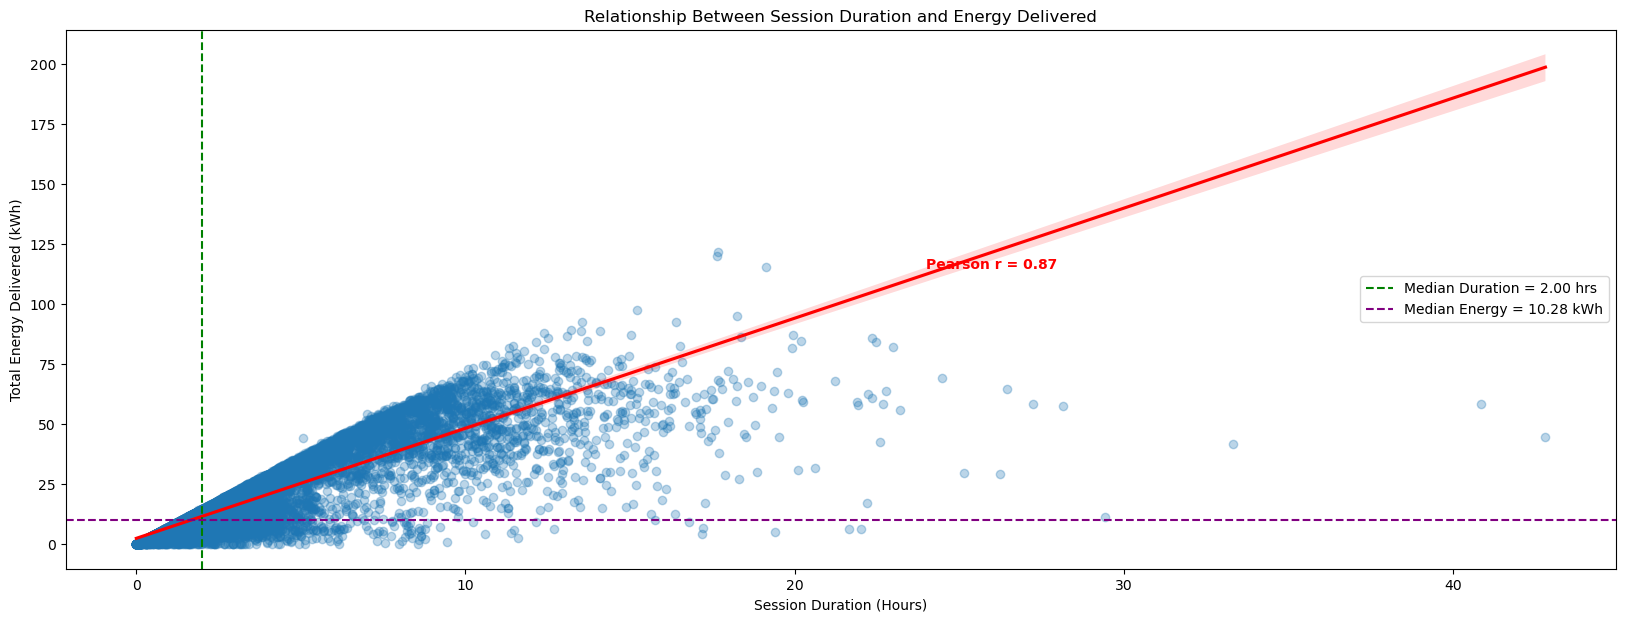

In [28]:
# Calculate correlation
correlation = df["duration_hours"].corr(df["total_kwh"])

# Create scatter plot with regression line
plt.figure()

sns.regplot(
    data=df,
    x="duration_hours",
    y="total_kwh",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

# Add median session duration
plt.axvline(
    median_duration,
    color="green",
    linestyle="--",
    label=f"Median Duration = {median_duration:.2f} hrs"
)

# Add median energy delivered
plt.axhline(
    median_kwh,
    color="purple",
    linestyle="--",
    label=f"Median Energy = {median_kwh:.2f} kWh"
)

# Add correlation label near the regression line
plt.text(
    24,
    115,
    #f"Correlation = {correlation:.2f}"
    f"Pearson r = {correlation:.2f}",
    color="red",
    fontweight="bold"
)

# Add title and labels
plt.title("Relationship Between Session Duration and Energy Delivered")
plt.xlabel("Session Duration (Hours)")
plt.ylabel("Total Energy Delivered (kWh)")

plt.legend()
plt.show()

### Duration–energy relationship

Session duration and energy delivered have a strong positive relationship (**Pearson r ≈ 0.87**). Longer sessions generally deliver more energy, although individual sessions still vary around the overall trend.

The median reference lines provide a simple visual benchmark for a typical session:
- median duration ≈ **2.00 hours**
- median energy ≈ **10.28 kWh**


In [29]:
# Calculate quartiles for session duration
duration_q1 = df["duration_hours"].quantile(0.25)
duration_q3 = df["duration_hours"].quantile(0.75)

# Calculate the interquartile range
duration_iqr = duration_q3 - duration_q1

# Calculate lower and upper outlier limits
duration_lower = duration_q1 - (1.5 * duration_iqr)
duration_upper = duration_q3 + (1.5 * duration_iqr)


# Calculate quartiles for energy delivered
kwh_q1 = df["total_kwh"].quantile(0.25)
kwh_q3 = df["total_kwh"].quantile(0.75)

# Calculate the interquartile range
kwh_iqr = kwh_q3 - kwh_q1

# Calculate lower and upper outlier limits
kwh_lower = kwh_q1 - (1.5 * kwh_iqr)
kwh_upper = kwh_q3 + (1.5 * kwh_iqr)


# Display the results
print(f"Duration Q1: {duration_q1:.2f} hours")
print(f"Duration Q3: {duration_q3:.2f} hours")
print(f"Duration IQR: {duration_iqr:.2f} hours")
print(f"Duration Upper Outlier Limit: {duration_upper:.2f} hours")

print()

print(f"Energy Q1: {kwh_q1:.2f} kWh")
print(f"Energy Q3: {kwh_q3:.2f} kWh")
print(f"Energy IQR: {kwh_iqr:.2f} kWh")
print(f"Energy Upper Outlier Limit: {kwh_upper:.2f} kWh")

Duration Q1: 1.03 hours
Duration Q3: 3.64 hours
Duration IQR: 2.61 hours
Duration Upper Outlier Limit: 7.56 hours

Energy Q1: 4.87 kWh
Energy Q3: 21.65 kWh
Energy IQR: 16.78 kWh
Energy Upper Outlier Limit: 46.83 kWh


In [30]:
# Count duration outliers
duration_outliers = (
    df["duration_hours"] > duration_upper
).sum()

# Count energy outliers
kwh_outliers = (
    df["total_kwh"] > kwh_upper
).sum()

print("Duration outliers:", duration_outliers)
print("Energy outliers:", kwh_outliers)

Duration outliers: 1666
Energy outliers: 1298


In [31]:
# Create outlier flags
df["duration_outlier"] = df["duration_hours"] > duration_upper
df["energy_outlier"] = df["total_kwh"] > kwh_upper

# Count sessions that are outliers in both measures
both_outliers = (
    df["duration_outlier"] &
    df["energy_outlier"]
).sum()

print("Duration outliers:", df["duration_outlier"].sum())
print("Energy outliers:", df["energy_outlier"].sum())
print("Outliers in both duration and energy:", both_outliers)

Duration outliers: 1666
Energy outliers: 1298
Outliers in both duration and energy: 1064


## Q3 Conclusion

A typical charging session lasts about **2 hours** and delivers roughly **10.3 kWh** based on the medians.

Using the 1.5×IQR rule:
- sessions longer than about **7.56 hours** are statistical duration outliers;
- sessions delivering more than about **46.83 kWh** are statistical energy outliers.

There are **1,064 sessions** that are outliers on both measures. These records are retained because statistical outliers are not automatically data errors; they may represent legitimate long-duration or high-energy charging behaviour.


---

# Q4. What factors appear to explain differences in performance across sites and stations?

This section will compare high- and low-performing locations to identify patterns that may help explain utilization differences.

### Potential factors
- Site/location
- Number of stations at a site
- Session duration
- Energy delivered per session
- Day-of-week usage
- Hour-of-day usage
- End reasons
- Geographic context and nearby amenities — to be handled in a separate geospatial notebook.

The analysis will distinguish observed relationships from causal claims.


In [32]:
df.columns

Index(['transaction_id', 'session_id', 'charging_time', 'province_or_state',
       'owner', 'site', 'address', 'point_x', 'point_y', 'station',
       'card_number', 'end_reason', 'total_kwh', 'session_start',
       'session_end', 'duration_hours', 'start_hour', 'day_of_week',
       'month_year', 'address_clean', 'duration_outlier', 'energy_outlier'],
      dtype='object')

In [33]:
df

,transaction_id,session_id,charging_time,province_or_state,owner,site,address,point_x,point_y,station,...,total_kwh,session_start,session_end,duration_hours,start_hour,day_of_week,month_year,address_clean,duration_outlier,energy_outlier
0,8971546,ce499016-c0fe-4b76-9224-e8e9e8b1caa3,0:33:48,ON,City of Ottawa,City of Ottawa - 190 Richmond Road,190 Richmond Rd.,-75.7475,45.39466,AAA-14533,...,4.06440,2022-05-01 11:36:44,2022-05-01 12:10:32,0.563333,11,Sunday,2022-05,190 Richmond Rd,False,False
1,8971910,daeaa8b8-2528-4b2a-a1ea-4aab820f188f,0:50:07,ON,City of Ottawa,City of Ottawa - 245 Crichton St.,245 Crichton St.,-75.6823,45.43930,AAA-14506,...,2.92454,2022-05-01 12:07:03,2022-05-01 12:57:10,0.835278,12,Sunday,2022-05,245 Crichton St,False,False
2,8972766,5e4d5163-2c67-4049-ac1d-41193e6064d9,2:57:01,ON,City of Ottawa,City of Ottawa - 186 Main St.,186 Main St.,-75.6782,45.40886,AAA-14503,...,20.59820,2022-05-01 11:43:33,2022-05-01 14:40:34,2.950278,11,Sunday,2022-05,186 Main St,False,False
3,8972887,c83802a2-1f6d-4c24-bba2-5bff14371aec,1:36:12,ON,City of Ottawa,City of Ottawa - 301 Laurier Avenue,301 Laurier Ave. E,-75.6793,45.42710,AAA-14508,...,11.52725,2022-05-01 13:21:37,2022-05-01 14:57:49,1.603333,13,Sunday,2022-05,301 Laurier Ave E,False,False
4,8973165,24715a5e-ccee-420f-ac17-0414a5ec14aa,0:34:59,ON,City of Ottawa,City of Ottawa - 2nd Avenue Parking Garage,170 Second Ave.,-75.6893,45.40323,AAB-20483,...,3.17881,2022-05-01 15:00:19,2022-05-01 15:35:18,0.583056,15,Sunday,2022-05,170 Second Ave,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22444,19797014,b68ff4eb-f956-419f-93e1-823b04de0b76,9:04:54,ON,City of Ottawa,City of Ottawa - 1551 Lycée Place,1551 Lycee Place,-75.6623,45.40838,AAA-14510,...,36.09781,2024-06-23 21:38:59,2024-06-24 06:43:53,9.081667,21,Sunday,2024-06,1551 Lycee Place,True,False
22445,19797542,cb4c229b-458c-40a1-91f2-d1164c4c3963,10:41:47,ON,City of Ottawa,City of Ottawa - 170 Primrose Ave.,170 Primrose Ave.,-75.7136,45.41067,AAA-14502,...,61.54947,2024-06-23 21:15:54,2024-06-24 07:57:41,10.696389,21,Sunday,2024-06,170 Primrose Ave,True,True
22446,19797723,3d0ab93b-2376-4a25-8a37-732b9e0bb7f3,0:00:29,ON,City of Ottawa,City of Ottawa - 6 Oak St.,6 Oak St.,-75.7136,45.41067,AAA-14521,...,0.00353,2024-06-24 08:14:15,2024-06-24 08:14:44,0.008056,8,Monday,2024-06,6 Oak St,False,False
22447,19797998,4ff71670-9a49-4ada-bcb7-204ab25f1b14,10:37:17,ON,City of Ottawa,City of Ottawa - 186 Main St.,186 Main St.,-75.6782,45.40886,AAA-14505,...,74.45688,2024-06-23 22:05:14,2024-06-24 08:42:31,10.621389,22,Sunday,2024-06,186 Main St,True,True


In [34]:
# Count the number of unique stations at each site
stations_per_site = (
    df.groupby("site")["station"]
    .nunique()
    .reset_index(name="station_count")
)

# Merge station count into the site summary table
site_performance = site_usage.merge(
    stations_per_site,
    on="site",
    how="left"
)

site_performance.head()

,site,sessions,total_kwh,avg_duration_hours,total_hours,session_rank,energy_rank,hours_rank,avg_usage_rank,station_count
0,City of Ottawa - 118 Cartier St.,2546,40702.58792,2.860178,7282.012222,19.0,19.0,19.0,19.000000,2
1,City Hall - Ottawa,2507,25228.29039,1.855507,4651.755000,18.0,14.0,14.0,15.333333,1
2,City of Ottawa - 301 Laurier Avenue,2068,32687.79148,2.980456,6163.583611,17.0,17.0,17.0,17.000000,2
3,City of Ottawa - 122 Daly Ave.,1868,34562.97277,3.432877,6412.614444,16.0,18.0,18.0,17.333333,2
4,City of Ottawa - 6 Oak St.,1573,26014.46440,2.826546,4446.156667,15.0,15.0,13.0,14.333333,2


In [35]:
# Check correlation between station count and site performance
station_session_corr = site_performance["station_count"].corr(
    site_performance["sessions"]
)

station_kwh_corr = site_performance["station_count"].corr(
    site_performance["total_kwh"]
)

print(f"Correlation: Station Count vs Sessions = {station_session_corr:.2f}")
print(f"Correlation: Station Count vs Total kWh = {station_kwh_corr:.2f}")

Correlation: Station Count vs Sessions = -0.04
Correlation: Station Count vs Total kWh = 0.17


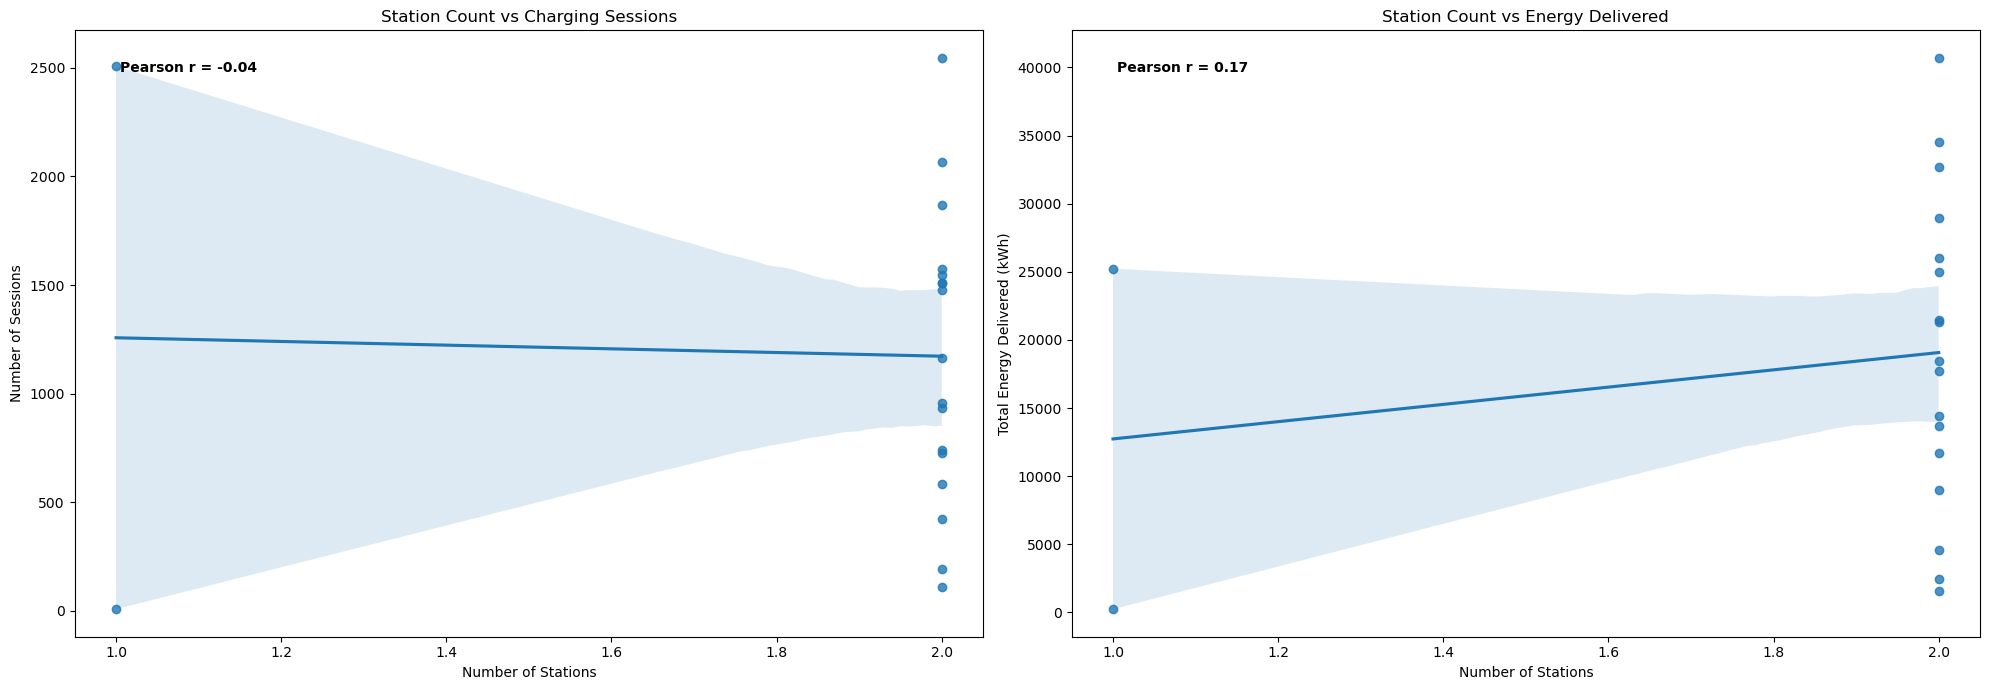

In [36]:
# Create side-by-side scatter plots
fig, axes = plt.subplots(1, 2)

# Station count vs sessions
sns.regplot(
    data=site_performance,
    x="station_count",
    y="sessions",
    ax=axes[0]
)

axes[0].set_title("Station Count vs Charging Sessions")
axes[0].set_xlabel("Number of Stations")
axes[0].set_ylabel("Number of Sessions")

# Add correlation value
axes[0].text(
    0.05,
    0.95,
    f"Pearson r = {station_session_corr:.2f}",
    transform=axes[0].transAxes,
    va="top",
    fontweight="bold"
)

# Station count vs total energy
sns.regplot(
    data=site_performance,
    x="station_count",
    y="total_kwh",
    ax=axes[1]
)

axes[1].set_title("Station Count vs Energy Delivered")
axes[1].set_xlabel("Number of Stations")
axes[1].set_ylabel("Total Energy Delivered (kWh)")

# Add correlation value
axes[1].text(
    0.05,
    0.95,
    f"Pearson r = {station_kwh_corr:.2f}",
    transform=axes[1].transAxes,
    va="top",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Observed station count limitation

The correlations between observed station count and performance are very weak:
- station count vs sessions: **r = -0.04**
- station count vs total kWh: **r = 0.17**

However, `station_count` is based only on distinct station IDs appearing in this usage dataset. A site may physically contain more charging ports than are represented here. For that reason, this variable is treated as an observed-data proxy rather than true installed capacity.


In [37]:
# Set the day order so the chart appears Monday to Sunday
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# Count charging sessions by day of week
day_usage = (
    df["day_of_week"]
    .value_counts()
    .reindex(day_order)
    .reset_index()
)

# Rename columns
day_usage.columns = ["day_of_week", "sessions"]

day_usage

,day_of_week,sessions
0,Monday,2659
1,Tuesday,2944
2,Wednesday,3092
3,Thursday,3083
4,Friday,3459
5,Saturday,3880
6,Sunday,3332


In [38]:
# Calculate total energy delivered by day of week
day_energy = (
    df.groupby("day_of_week")["total_kwh"]
    .sum()
    .reindex(day_order)
    .reset_index()
)

# Merge session count and energy into one table
day_summary = day_usage.merge(
    day_energy,
    on="day_of_week"
)

day_summary

,day_of_week,sessions,total_kwh
0,Monday,2659,42825.41842
1,Tuesday,2944,44744.91207
2,Wednesday,3092,46911.16466
3,Thursday,3083,46757.54122
4,Friday,3459,54408.38026
5,Saturday,3880,59780.78340
6,Sunday,3332,54269.59563


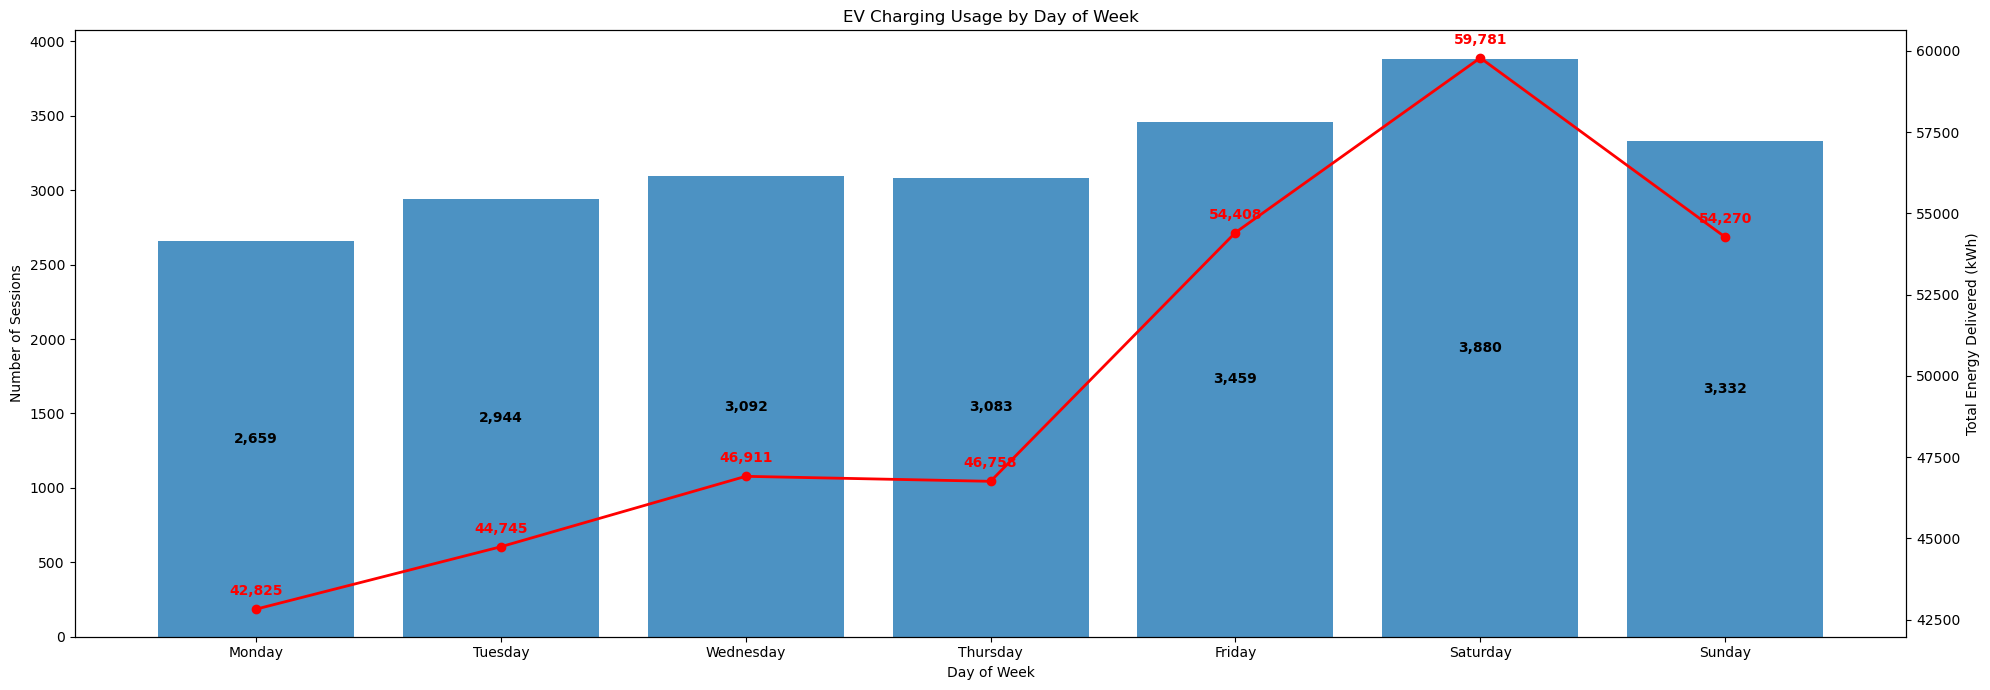

In [39]:
# Create combo chart for weekday usage
fig, ax1 = plt.subplots()

# Bar chart for charging sessions
bars = ax1.bar(
    day_summary["day_of_week"],
    day_summary["sessions"],
    alpha=0.8
)

ax1.set_title("EV Charging Usage by Day of Week")
ax1.set_xlabel("Day of Week")
ax1.set_ylabel("Number of Sessions")

# Add session labels inside the bars
for bar in bars:
    height = bar.get_height()

    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,
        f"{int(height):,}",
        ha="center",
        va="center",
        fontweight="bold"
    )

# Create second y-axis for energy delivered
ax2 = ax1.twinx()

# Plot total energy delivered
ax2.plot(
    day_summary["day_of_week"],
    day_summary["total_kwh"],
    marker="o",
    linewidth=2,
    color="red"
)

ax2.set_ylabel("Total Energy Delivered (kWh)")

# Add energy labels above the line
for x, y in zip(
    day_summary["day_of_week"],
    day_summary["total_kwh"]
):
    ax2.annotate(
        f"{y:,.0f}",
        xy=(x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color="red",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Day-of-week pattern

Charging activity generally increases through the week and peaks on **Saturday**. Total energy delivered follows a similar pattern, suggesting that the weekend increase is driven largely by higher session volume rather than a dramatic change in energy per session.


In [40]:
# Count charging sessions by start hour
hour_usage = (
    df.groupby("start_hour")
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum")
    )
    .reset_index()
)

hour_usage

,start_hour,sessions,total_kwh
0,0,172,5370.26101
1,1,87,2390.85620
2,2,66,1830.66941
3,3,64,1366.79586
4,4,45,1172.18513
5,5,84,1546.86680
6,6,319,5227.51172
7,7,673,11824.31397
8,8,1332,24722.52380
9,9,1589,26643.55777


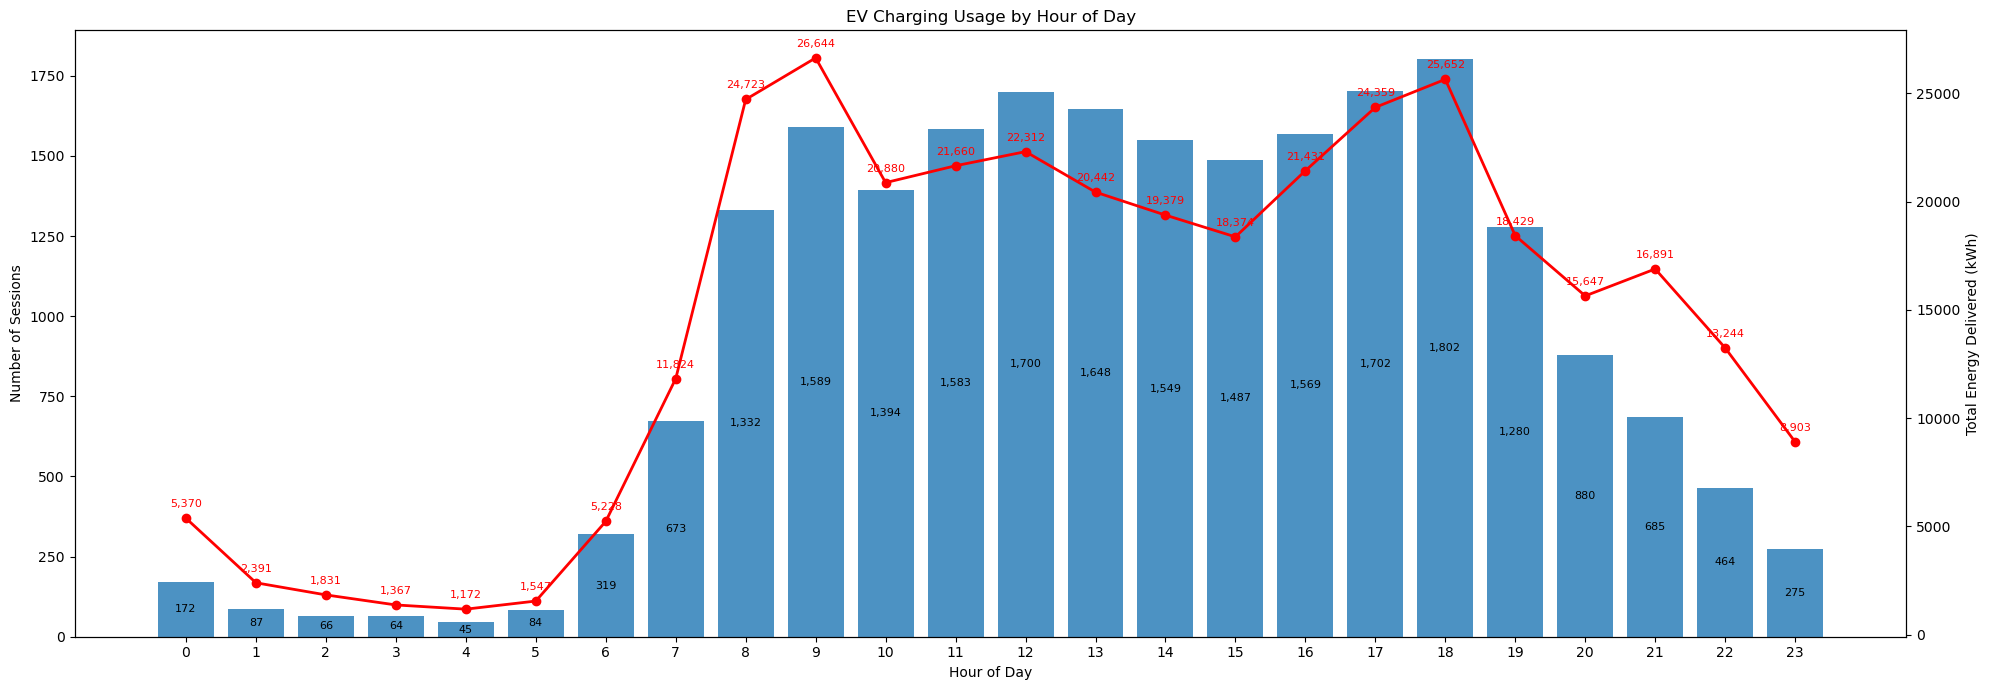

In [41]:
# Create combo chart for hourly usage
fig, ax1 = plt.subplots()

# Bar chart for number of sessions
bars = ax1.bar(
    hour_usage["start_hour"],
    hour_usage["sessions"],
    alpha=0.8
)

ax1.set_title("EV Charging Usage by Hour of Day")
ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("Number of Sessions")
ax1.set_xticks(range(0, 24))

# Add session labels inside the bars
for bar in bars:
    height = bar.get_height()

    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,
        f"{int(height):,}",
        ha="center",
        va="center",
        fontsize=8
    )

# Create second y-axis for energy delivered
ax2 = ax1.twinx()

# Plot total energy delivered
ax2.plot(
    hour_usage["start_hour"],
    hour_usage["total_kwh"],
    marker="o",
    linewidth=2,
    color="red"
)

ax2.set_ylabel("Total Energy Delivered (kWh)")

# Add energy labels above the line
for x, y in zip(
    hour_usage["start_hour"],
    hour_usage["total_kwh"]
):
    ax2.annotate(
        f"{y:,.0f}",
        xy=(x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        color="red",
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Hour-of-day pattern

Charging demand shows strong daytime activity, with session counts rising sharply from the morning and remaining elevated through the afternoon and early evening.

The highest session count occurs around **6 PM**, while total energy delivered reaches a strong peak earlier in the day. This difference motivates a closer look at energy per session and session duration by start hour.


In [42]:
# Calculate average energy delivered per session by hour of day
hour_usage["avg_kwh_per_session"] = (
    hour_usage["total_kwh"] / hour_usage["sessions"]
)

hour_usage[
    ["start_hour", "sessions", "total_kwh", "avg_kwh_per_session"]
]

,start_hour,sessions,total_kwh,avg_kwh_per_session
0,0,172,5370.26101,31.222448
1,1,87,2390.85620,27.481106
2,2,66,1830.66941,27.737415
3,3,64,1366.79586,21.356185
4,4,45,1172.18513,26.048558
5,5,84,1546.86680,18.415081
6,6,319,5227.51172,16.387184
7,7,673,11824.31397,17.569560
8,8,1332,24722.52380,18.560453
9,9,1589,26643.55777,16.767500


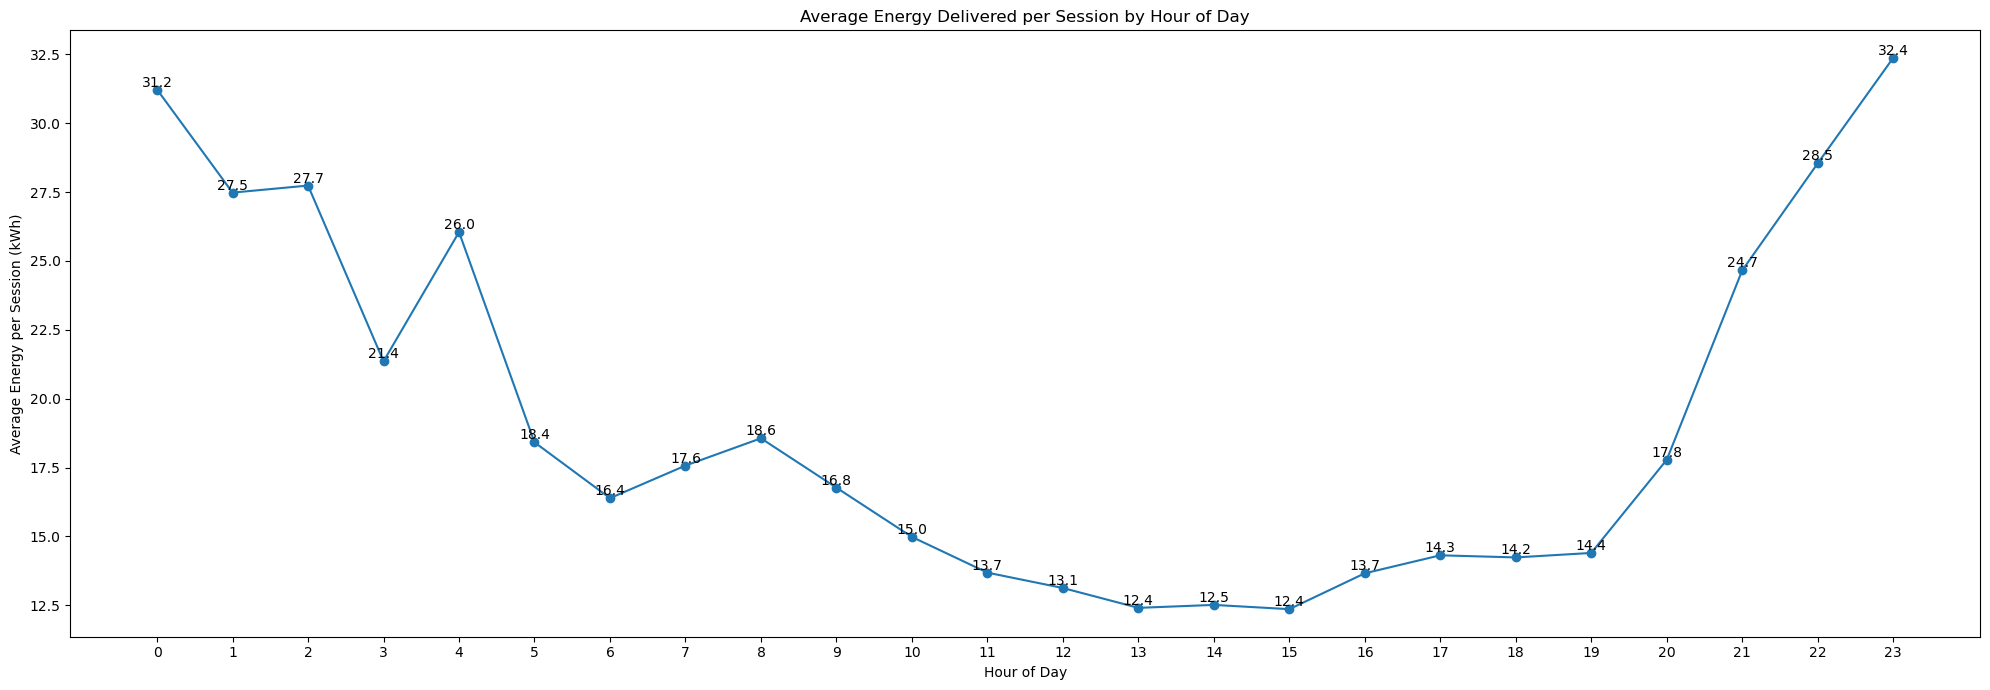

In [43]:
# Plot average energy delivered per session by hour of day
plt.figure()

plt.plot(
    hour_usage["start_hour"],
    hour_usage["avg_kwh_per_session"],
    marker="o"
)

# Add labels for each hour
for x, y in zip(
    hour_usage["start_hour"],
    hour_usage["avg_kwh_per_session"]
):
    plt.text(
        x,
        y,
        f"{y:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Average Energy Delivered per Session by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy per Session (kWh)")
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

In [44]:
# Estimate average charging rate for each session
df["avg_kw"] = df["total_kwh"] / df["duration_hours"]

# Average charging rate by start hour
hour_power = (
    df.groupby("start_hour")["avg_kw"]
    .mean()
    .reset_index()
)

hour_power

,start_hour,avg_kw
0,0,5.609671
1,1,5.299087
2,2,5.196167
3,3,5.659487
4,4,5.806016
5,5,6.199331
6,6,5.393568
7,7,5.528383
8,8,5.421648
9,9,5.477419


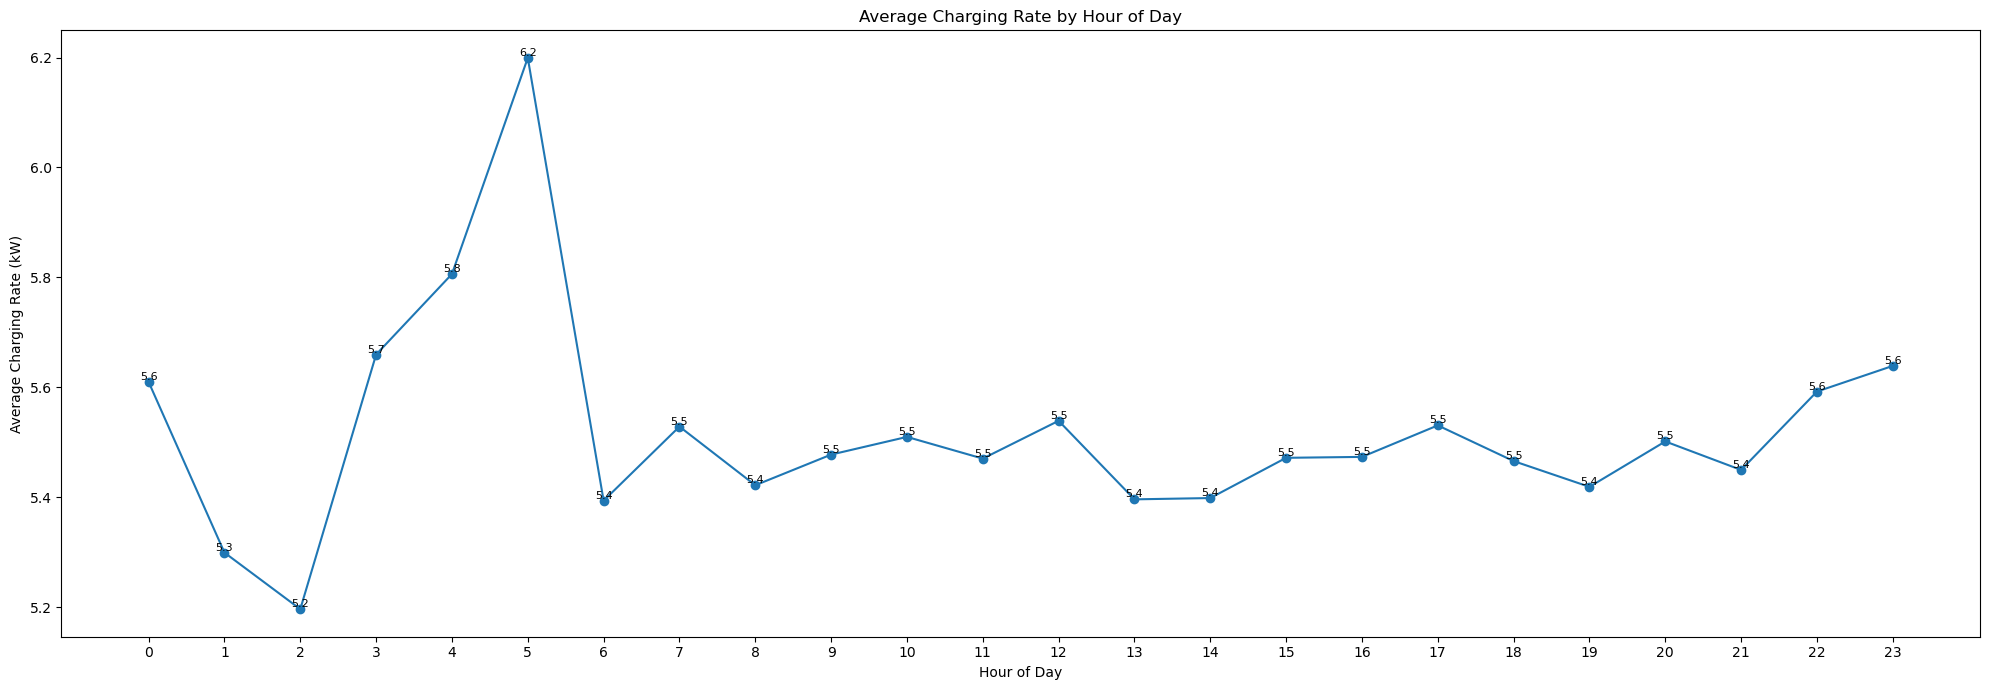

In [45]:
# Plot average charging rate by hour of day
plt.figure()

plt.plot(
    hour_power["start_hour"],
    hour_power["avg_kw"],
    marker="o"
)

# Add labels
for x, y in zip(
    hour_power["start_hour"],
    hour_power["avg_kw"]
):
    plt.text(
        x,
        y,
        f"{y:.1f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.title("Average Charging Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Charging Rate (kW)")
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

### Charging-rate interpretation

Estimated average charging rate remains relatively stable through most of the day, generally around the mid-5 kW range.

This provides little evidence of systematic time-of-day power throttling in the available data. The higher energy delivered during late-night sessions therefore appears to be explained more by **longer session duration** than by substantially higher charging power.


In [46]:
# Calculate average session duration by hour of day
hour_duration = (
    df.groupby("start_hour")["duration_hours"]
    .mean()
    .reset_index()
)

hour_duration

,start_hour,duration_hours
0,0,5.710438
1,1,5.365971
2,2,5.308110
3,3,3.620716
4,4,4.430475
5,5,3.090721
6,6,3.071760
7,7,3.121017
8,8,3.258573
9,9,2.995378


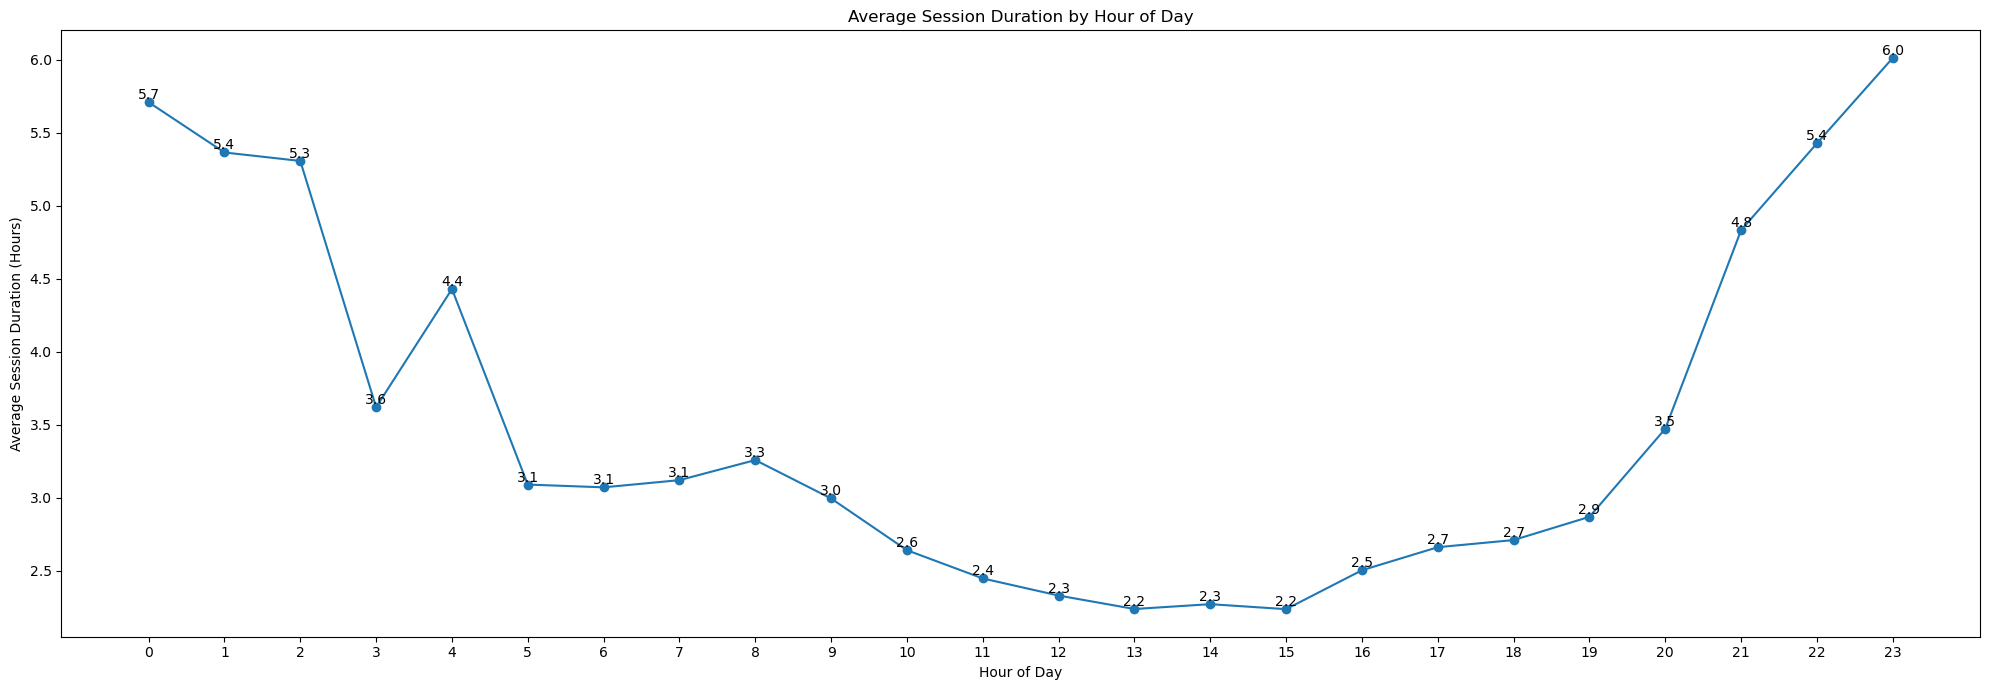

In [47]:
# Plot average session duration by hour of day
plt.figure()

plt.plot(
    hour_duration["start_hour"],
    hour_duration["duration_hours"],
    marker="o"
)

# Add value labels
for x, y in zip(
    hour_duration["start_hour"],
    hour_duration["duration_hours"]
):
    plt.text(
        x,
        y,
        f"{y:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Average Session Duration by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Session Duration (Hours)")
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

### Late-night duration pattern

Average session duration is much longer for sessions beginning late at night. Sessions starting around 9 PM through the early morning tend to remain connected considerably longer than daytime sessions.

For this analysis, **Late Night** is defined as **9:00 PM to 5:59 AM**.

Potential explanations such as hotels, long-term parking, hospitals, residential-adjacent locations, or other nearby amenities are hypotheses only and will be explored separately in the geospatial analysis.


In [48]:
# Create a late-night session group
late_night_sessions = df[
    df["start_hour"].isin([21, 22, 23, 0, 1, 2, 3, 4, 5])
].copy()

# Check the most common end reasons
late_night_end_reasons = (
    late_night_sessions["end_reason"]
    .value_counts()
)

late_night_end_reasons

end_reason
The charging cable was disconnected and put back in the station.    1027
Charging ended by vehicle                                            905
Stopped by operator                                                   10
Name: count, dtype: int64

In [49]:
# Calculate end-reason percentages for late-night sessions
late_night_end_reason_pct = (
    late_night_sessions["end_reason"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

late_night_end_reason_pct

end_reason
The charging cable was disconnected and put back in the station.    52.9
Charging ended by vehicle                                           46.6
Stopped by operator                                                  0.5
Name: proportion, dtype: float64

In [50]:
# Calculate end-reason percentages for all sessions
all_end_reason_pct = (
    df["end_reason"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

# Compare all sessions with late-night sessions
end_reason_comparison = pd.DataFrame({
    "all_sessions_pct": all_end_reason_pct,
    "late_night_pct": late_night_end_reason_pct
}).fillna(0)

end_reason_comparison

,all_sessions_pct,late_night_pct
end_reason,,
Charging ended by vehicle,38.9,46.6
Charging stopped following a ground fault during the first seconds,0.0,0.0
Stopped by operator,0.5,0.5
The charging cable was disconnected and put back in the station.,60.5,52.9


In [51]:
# Label sessions as late night or non-late night
df["time_group"] = np.where(
    df["start_hour"].isin([21, 22, 23, 0, 1, 2, 3, 4, 5]),
    "Late Night",
    "Other Hours"
)

# Create a table of end reasons by time group
end_reason_table = pd.crosstab(
    df["time_group"],
    df["end_reason"]
)

end_reason_table

end_reason,Charging ended by vehicle,Charging stopped following a ground fault during the first seconds,Stopped by operator,The charging cable was disconnected and put back in the station.
time_group,,,,
Late Night,905,0,10,1027
Other Hours,7836,2,110,12559


In [52]:
from scipy.stats import chi2_contingency

# Test whether end reason is associated with time of day
chi2, p_value, dof, expected = chi2_contingency(end_reason_table)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.4f}")

Chi-square statistic: 52.76
P-value: 0.0000


In [53]:
# Convert the crosstab counts into row percentages
end_reason_pct = (
    end_reason_table.div(end_reason_table.sum(axis=1), axis=0) * 100
)

end_reason_pct

end_reason,Charging ended by vehicle,Charging stopped following a ground fault during the first seconds,Stopped by operator,The charging cable was disconnected and put back in the station.
time_group,,,,
Late Night,46.601442,0.000000,0.514933,52.883625
Other Hours,38.211342,0.009753,0.536402,61.242503


In [54]:
# Define late-night hours as 9:00 PM to 5:59 AM
late_night_hours = [21, 22, 23, 0, 1, 2, 3, 4, 5]

# Create time groups
df["time_group"] = np.where(
    df["start_hour"].isin(late_night_hours),
    "Late Night (9:00 PM–5:59 AM)",
    "Other Hours (6:00 AM–8:59 PM)"
)

# Summarize charging behaviour by time group and end reason
end_reason_summary = (
    df.groupby(["time_group", "end_reason"])
    .agg(
        sessions=("session_id", "count"),
        avg_kwh=("total_kwh", "mean"),
        avg_duration=("duration_hours", "mean"),
        avg_kw=("avg_kw", "mean")
    )
    .reset_index()
)

# Calculate total sessions within each time group
end_reason_summary["group_total"] = (
    end_reason_summary
    .groupby("time_group")["sessions"]
    .transform("sum")
)

# Calculate each end reason as a percentage of its time group
end_reason_summary["percentage"] = (
    end_reason_summary["sessions"]
    / end_reason_summary["group_total"]
    * 100
)

end_reason_summary

,time_group,end_reason,sessions,avg_kwh,avg_duration,avg_kw,group_total,percentage
0,Late Night (9:00 PM–5:59 AM),Charging ended by vehicle,905,32.581461,6.459900,5.229123,1942,46.601442
1,Late Night (9:00 PM–5:59 AM),Stopped by operator,10,11.047272,1.630778,5.768240,1942,0.514933
2,Late Night (9:00 PM–5:59 AM),The charging cable was disconnected and put ba...,1027,22.510851,4.003502,5.843566,1942,52.883625
3,Other Hours (6:00 AM–8:59 PM),Charging ended by vehicle,7836,16.449857,3.366855,4.968093,20507,38.211342
4,Other Hours (6:00 AM–8:59 PM),Charging stopped following a ground fault duri...,2,0.001300,0.003472,0.936000,20507,0.009753
5,Other Hours (6:00 AM–8:59 PM),Stopped by operator,110,3.307201,0.650066,4.701711,20507,0.536402
6,Other Hours (6:00 AM–8:59 PM),The charging cable was disconnected and put ba...,12559,13.354374,2.217494,5.787949,20507,61.242503


In [55]:
# Create interactive grouped bar chart
fig = px.bar(
    end_reason_summary,
    x="time_group",
    y="percentage",
    color="end_reason",
    barmode="group",
    title="End Reasons: Late Night vs Other Hours",
    custom_data=[
        "sessions",
        "avg_kwh",
        "avg_duration",
        "avg_kw"
    ]
)

# Customize the hover information
fig.update_traces(
    hovertemplate=
    "<b>%{x}</b><br>" +
    "End Reason: %{fullData.name}<br>" +
    "Share of Sessions: %{y:.1f}%<br>" +
    "Number of Sessions: %{customdata[0]:,}<br>" +
    "Avg Energy: %{customdata[1]:.2f} kWh<br>" +
    "Avg Duration: %{customdata[2]:.2f} hours<br>" +
    "Avg Charging Rate: %{customdata[3]:.2f} kW<br>" +
    "<extra></extra>"
)

# Update labels
fig.update_layout(
    xaxis_title="Time Group",
    yaxis_title="Percentage of Sessions",
    legend_title="End Reason"
)

fig.show()

## Q4 Conclusion

Several behavioural factors are associated with site and session performance:

- usage is stronger toward the end of the week, with Saturday showing the highest activity;
- daytime hours generate the largest number of sessions;
- late-night sessions deliver more energy per session primarily because they last longer;
- average charging rate remains relatively stable across the day;
- end reason is significantly associated with time group (**χ² ≈ 52.76, p < 0.001**);
- late-night sessions are more likely to end because the **vehicle ends charging** and less likely to end because the cable is manually disconnected.

These relationships are descriptive and should not be interpreted as proof of causation.

**Geographic context and nearby amenities are intentionally deferred to a separate geospatial notebook.**


---

# Q5. Can historical charging-session data be used to forecast near-term charging demand?

This section will test whether historical usage contains enough structure to support a simple near-term demand forecast.

### Potential forecasting targets
- Monthly charging sessions
- Monthly total kWh
- Daily or weekly demand, if the time series is sufficiently complete

### Planned workflow
- Select an appropriate time aggregation
- Examine trend and seasonality
- Create a chronological train/test split
- Build a simple baseline forecast
- Compare predicted vs actual demand using suitable error metrics

The objective is not to build an unnecessarily complex model, but to determine whether the historical data has practical predictive value.


In [63]:
# Create a weekly time series
weekly_demand = (
    df.set_index("session_start")
    .resample("W")
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum")
    )
    .reset_index()
)

# Display the first few rows
weekly_demand.head(10)

,session_start,sessions,total_kwh
0,2022-01-02,6,39.33260
1,2022-01-09,15,200.43364
2,2022-01-16,12,153.42587
3,2022-01-23,17,295.60152
4,2022-01-30,18,312.04106
5,2022-02-06,13,240.37643
6,2022-02-13,14,230.14200
7,2022-02-20,13,183.86501
8,2022-02-27,16,257.43651
9,2022-03-06,13,157.15518


In [57]:
# Check the number of weekly observations
print("Number of weeks:", len(weekly_demand))

# Check the date range
print("Start date:", weekly_demand["session_start"].min())
print("End date:", weekly_demand["session_start"].max())

Number of weeks: 131
Start date: 2022-01-02 00:00:00
End date: 2024-06-30 00:00:00


In [58]:
# Check for weeks with zero sessions
zero_session_weeks = (weekly_demand["sessions"] == 0).sum()

print("Weeks with zero sessions:", zero_session_weeks)

Weeks with zero sessions: 0


In [ ]:
# Visualizing the weekly pattern/trend by create a 4-week rolling average
weekly_demand["sessions_4wk_avg"] = (
    weekly_demand["sessions"]
    .rolling(window=4)
    .mean()
)

weekly_demand["kwh_4wk_avg"] = (
    weekly_demand["total_kwh"]
    .rolling(window=4)
    .mean()
)

# Why are we using a 4-week rolling average?

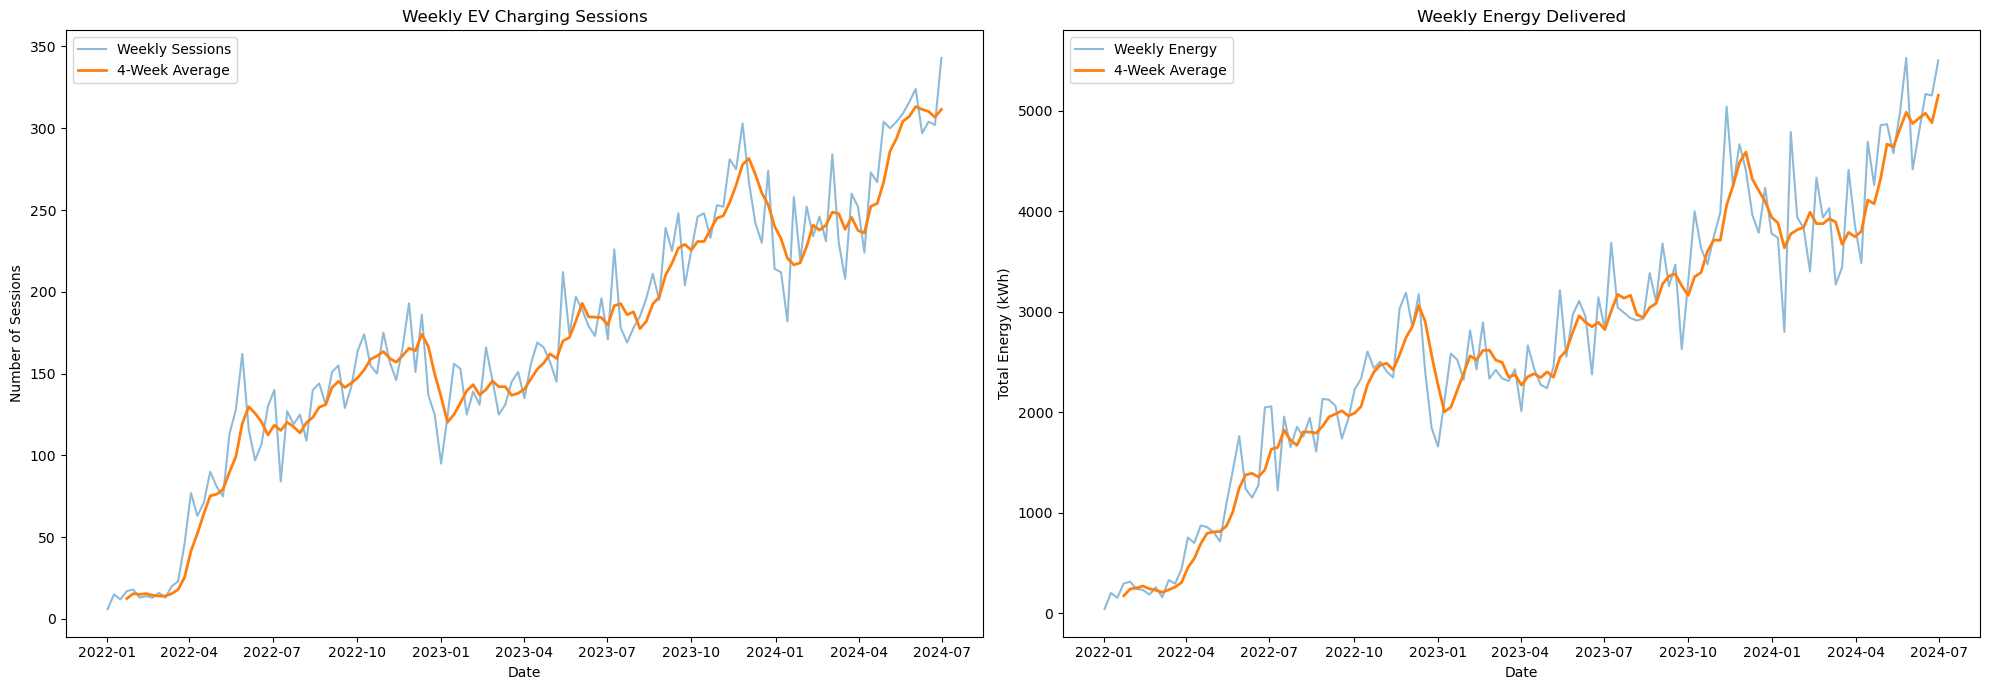

In [60]:
# Create side-by-side weekly demand charts
fig, axes = plt.subplots(1, 2)

# Weekly charging sessions
axes[0].plot(
    weekly_demand["session_start"],
    weekly_demand["sessions"],
    alpha=0.5,
    label="Weekly Sessions"
)

axes[0].plot(
    weekly_demand["session_start"],
    weekly_demand["sessions_4wk_avg"],
    linewidth=2,
    label="4-Week Average"
)

axes[0].set_title("Weekly EV Charging Sessions")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Number of Sessions")
axes[0].legend()


# Weekly energy delivered
axes[1].plot(
    weekly_demand["session_start"],
    weekly_demand["total_kwh"],
    alpha=0.5,
    label="Weekly Energy"
)

axes[1].plot(
    weekly_demand["session_start"],
    weekly_demand["kwh_4wk_avg"],
    linewidth=2,
    label="4-Week Average"
)

axes[1].set_title("Weekly Energy Delivered")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Total Energy (kWh)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Weekly-series note

The forecasting series contains **131 weekly observations** from January 2022 through June 2024, with no zero-session weeks.

The chart plots every weekly observation. Matplotlib displays only selected date labels on the x-axis for readability, so the wider spacing between visible date labels does **not** mean the data was aggregated quarterly or every few months.


In [64]:
# Set the number of weeks to keep for testing
test_weeks = 12

# Split the data chronologically

# Training data:
# Take all weekly rows from the beginning,
# but stop before the final 12 weeks
train = weekly_demand.iloc[:-test_weeks].copy()

# Testing data:
# Take only the final 12 weeks
# These weeks are treated as the "future" we want to predict
test = weekly_demand.iloc[-test_weeks:].copy()

# Check the split
print("Training weeks:", len(train))
print("Testing weeks:", len(test))

print("\nTraining period:")
print(train["session_start"].min(), "to", train["session_start"].max())

print("\nTesting period:")
print(test["session_start"].min(), "to", test["session_start"].max())

Training weeks: 119
Testing weeks: 12

Training period:
2022-01-02 00:00:00 to 2024-04-07 00:00:00

Testing period:
2024-04-14 00:00:00 to 2024-06-30 00:00:00


### Why the train/test split is chronological

Time-series data should not be randomly shuffled before forecasting.

The first **119 weeks** are used for training and the final **12 weeks** are held out as the test period. This simulates a real forecasting situation: the model learns from the past and is evaluated on later, unseen observations.

The test period runs from **14 April 2024 to 30 June 2024**.


In [66]:
train

,session_start,sessions,total_kwh
0,2022-01-02,6,39.33260
1,2022-01-09,15,200.43364
2,2022-01-16,12,153.42587
3,2022-01-23,17,295.60152
4,2022-01-30,18,312.04106
...,...,...,...
114,2024-03-10,230,3270.43444
115,2024-03-17,208,3440.95481
116,2024-03-24,260,4409.29223
117,2024-03-31,252,3859.04328


In [67]:
test

,session_start,sessions,total_kwh
119,2024-04-14,273,4688.35360
120,2024-04-21,267,4258.09555
121,2024-04-28,304,4853.91863
122,2024-05-05,300,4864.70533
123,2024-05-12,304,4575.49177
124,2024-05-19,309,4968.69817
125,2024-05-26,316,5523.85585
126,2024-06-02,324,4413.76242
127,2024-06-09,297,4790.93346
128,2024-06-16,304,5164.13813


In [65]:
# Create a simple baseline forecast

# A baseline gives us a basic forecast to compare future models against.
# Here, we use the average demand from the most recent 4 training weeks.
# This assumes that near-term demand will be similar to recent demand.

# Get the last 4 weeks of charging sessions from the training data
# .tail(4) selects the final 4 rows
# .mean() calculates their average
baseline_sessions = train["sessions"].tail(4).mean()

# Get the last 4 weeks of energy delivered from the training data
# and calculate the average
baseline_kwh = train["total_kwh"].tail(4).mean()

# Display the baseline forecasts
print(f"Baseline Weekly Sessions: {baseline_sessions:.1f}")
print(f"Baseline Weekly Energy: {baseline_kwh:.1f} kWh")

Baseline Weekly Sessions: 236.0
Baseline Weekly Energy: 3798.1 kWh


### Baseline forecast

A baseline forecast provides a simple benchmark that more advanced models should improve upon.

The initial baseline uses the average of the final four training weeks and assumes near-term demand remains close to recent demand. Alternative 1-, 2-, and 4-week baselines are later compared to determine which simple benchmark performs best.


In [70]:
# Create baseline predictions for the test period

# Use the same baseline value for each of the 12 future test weeks
# This gives us a simple benchmark forecast
test["predicted_sessions"] = baseline_sessions
test["predicted_kwh"] = baseline_kwh

# Display the actual and predicted values
test[
    [
        "session_start",
        "sessions",
        "predicted_sessions",
        "total_kwh",
        "predicted_kwh"
    ]
]

,session_start,sessions,predicted_sessions,total_kwh,predicted_kwh
119,2024-04-14,273,236.0,4688.35360,3798.135855
120,2024-04-21,267,236.0,4258.09555,3798.135855
121,2024-04-28,304,236.0,4853.91863,3798.135855
122,2024-05-05,300,236.0,4864.70533,3798.135855
123,2024-05-12,304,236.0,4575.49177,3798.135855
124,2024-05-19,309,236.0,4968.69817,3798.135855
125,2024-05-26,316,236.0,5523.85585,3798.135855
126,2024-06-02,324,236.0,4413.76242,3798.135855
127,2024-06-09,297,236.0,4790.93346,3798.135855
128,2024-06-16,304,236.0,5164.13813,3798.135855


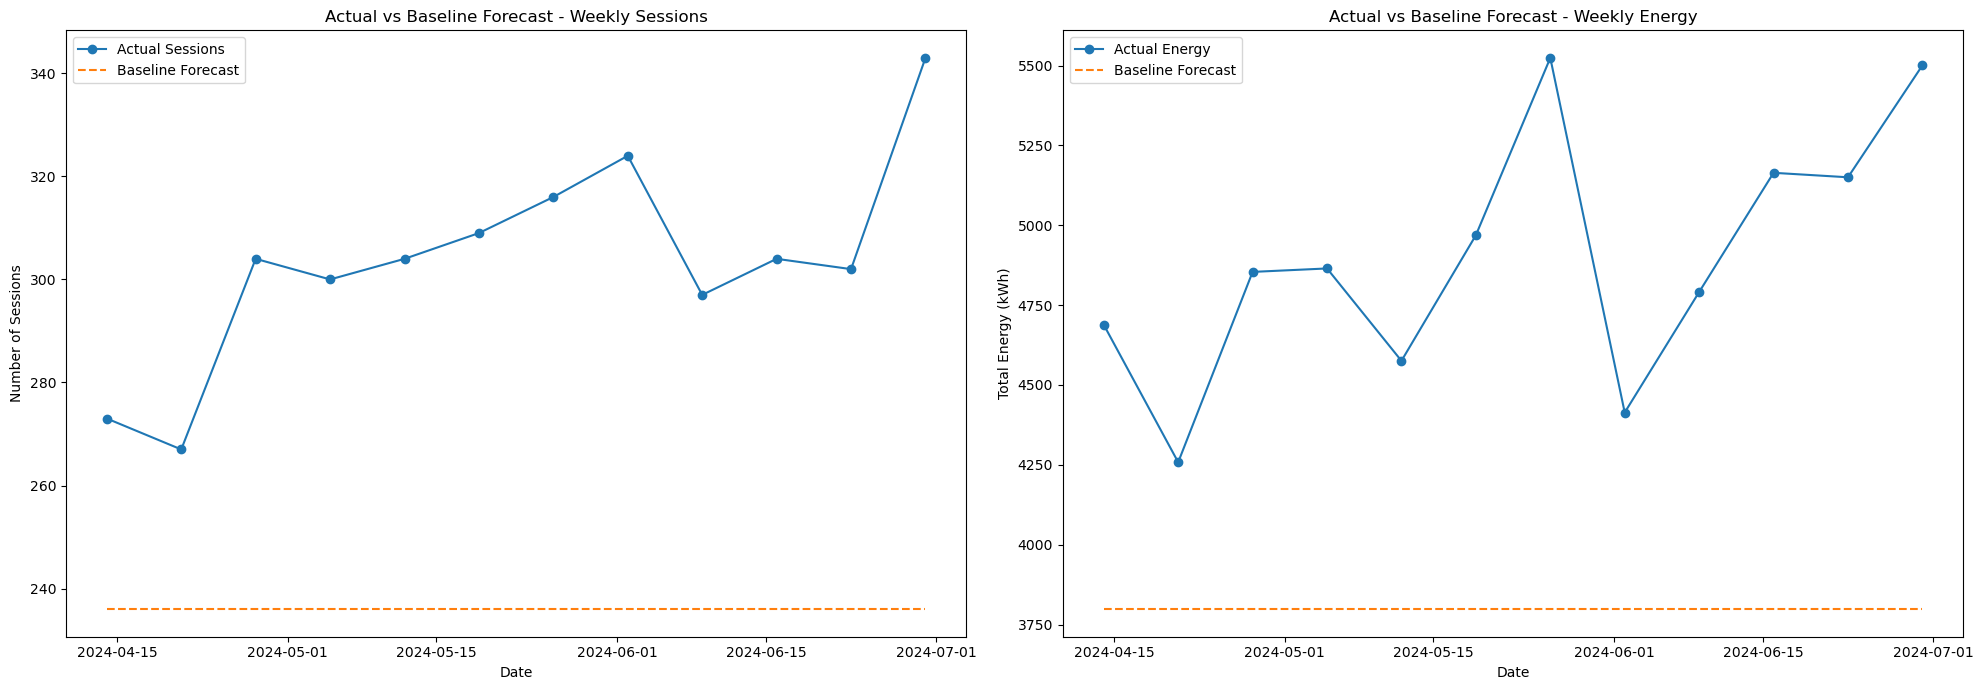

In [71]:
# Create side-by-side charts to compare actual and predicted demand
fig, axes = plt.subplots(1, 2)

# -----------------------------
# Weekly Charging Sessions
# -----------------------------
axes[0].plot(
    test["session_start"],
    test["sessions"],
    marker="o",
    label="Actual Sessions"
)

axes[0].plot(
    test["session_start"],
    test["predicted_sessions"],
    linestyle="--",
    label="Baseline Forecast"
)

axes[0].set_title("Actual vs Baseline Forecast - Weekly Sessions")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Number of Sessions")
axes[0].legend()


# -----------------------------
# Weekly Energy Delivered
# -----------------------------
axes[1].plot(
    test["session_start"],
    test["total_kwh"],
    marker="o",
    label="Actual Energy"
)

axes[1].plot(
    test["session_start"],
    test["predicted_kwh"],
    linestyle="--",
    label="Baseline Forecast"
)

axes[1].set_title("Actual vs Baseline Forecast - Weekly Energy")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Total Energy (kWh)")
axes[1].legend()


plt.tight_layout()
plt.show()

In [72]:
"""Quantify the error using two conventional metrics: MAE and RMSE."""
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate forecast errors for weekly sessions

# MAE = average absolute difference between actual and predicted values
sessions_mae = mean_absolute_error(
    test["sessions"],
    test["predicted_sessions"]
)

# RMSE gives more weight to larger prediction errors
sessions_rmse = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["predicted_sessions"]
    )
)


# Calculate forecast errors for weekly energy delivered

kwh_mae = mean_absolute_error(
    test["total_kwh"],
    test["predicted_kwh"]
)

kwh_rmse = np.sqrt(
    mean_squared_error(
        test["total_kwh"],
        test["predicted_kwh"]
    )
)


# Display the baseline forecast errors
print(f"Sessions MAE: {sessions_mae:.2f}")
print(f"Sessions RMSE: {sessions_rmse:.2f}")

print()

print(f"Energy MAE: {kwh_mae:.2f} kWh")
print(f"Energy RMSE: {kwh_rmse:.2f} kWh")

Sessions MAE: 67.58
Sessions RMSE: 70.30

Energy MAE: 1097.91 kWh
Energy RMSE: 1160.65 kWh


### Forecast error metrics

Two conventional error measures are used:

- **MAE (Mean Absolute Error):** the average absolute difference between actual and predicted values.
- **RMSE (Root Mean Squared Error):** similar to MAE but gives greater weight to larger forecast errors.

Lower values indicate better forecast accuracy.


In [73]:
# Create a simple week number for the full time series
# Week 0 = first week, Week 1 = second week, and so on
weekly_demand["week_number"] = range(len(weekly_demand))

# Re-create the chronological train/test split
train = weekly_demand.iloc[:-test_weeks].copy()
test = weekly_demand.iloc[-test_weeks:].copy()

# Check the first few rows
weekly_demand[
    ["session_start", "week_number", "sessions", "total_kwh"]
].head()

,session_start,week_number,sessions,total_kwh
0,2022-01-02,0,6,39.33260
1,2022-01-09,1,15,200.43364
2,2022-01-16,2,12,153.42587
3,2022-01-23,3,17,295.60152
4,2022-01-30,4,18,312.04106


In [74]:
from sklearn.linear_model import LinearRegression

# Select the predictor for the model
# X contains the week number
X_train = train[["week_number"]]
X_test = test[["week_number"]]

# Select the target we want to predict
# y contains the weekly number of charging sessions
y_train = train["sessions"]
y_test = test["sessions"]

# Create the linear regression model
session_model = LinearRegression()

# Train the model using the historical training data
session_model.fit(X_train, y_train)

# Predict charging sessions for the 12 test weeks
test["predicted_sessions_lr"] = session_model.predict(X_test)

# Display actual and predicted session counts
test[
    [
        "session_start",
        "week_number",
        "sessions",
        "predicted_sessions_lr"
    ]
]

,session_start,week_number,sessions,predicted_sessions_lr
119,2024-04-14,119,273,271.093576
120,2024-04-21,120,267,272.977909
121,2024-04-28,121,304,274.862242
122,2024-05-05,122,300,276.746575
123,2024-05-12,123,304,278.630907
124,2024-05-19,124,309,280.515240
125,2024-05-26,125,316,282.399573
126,2024-06-02,126,324,284.283905
127,2024-06-09,127,297,286.168238
128,2024-06-16,128,304,288.052571


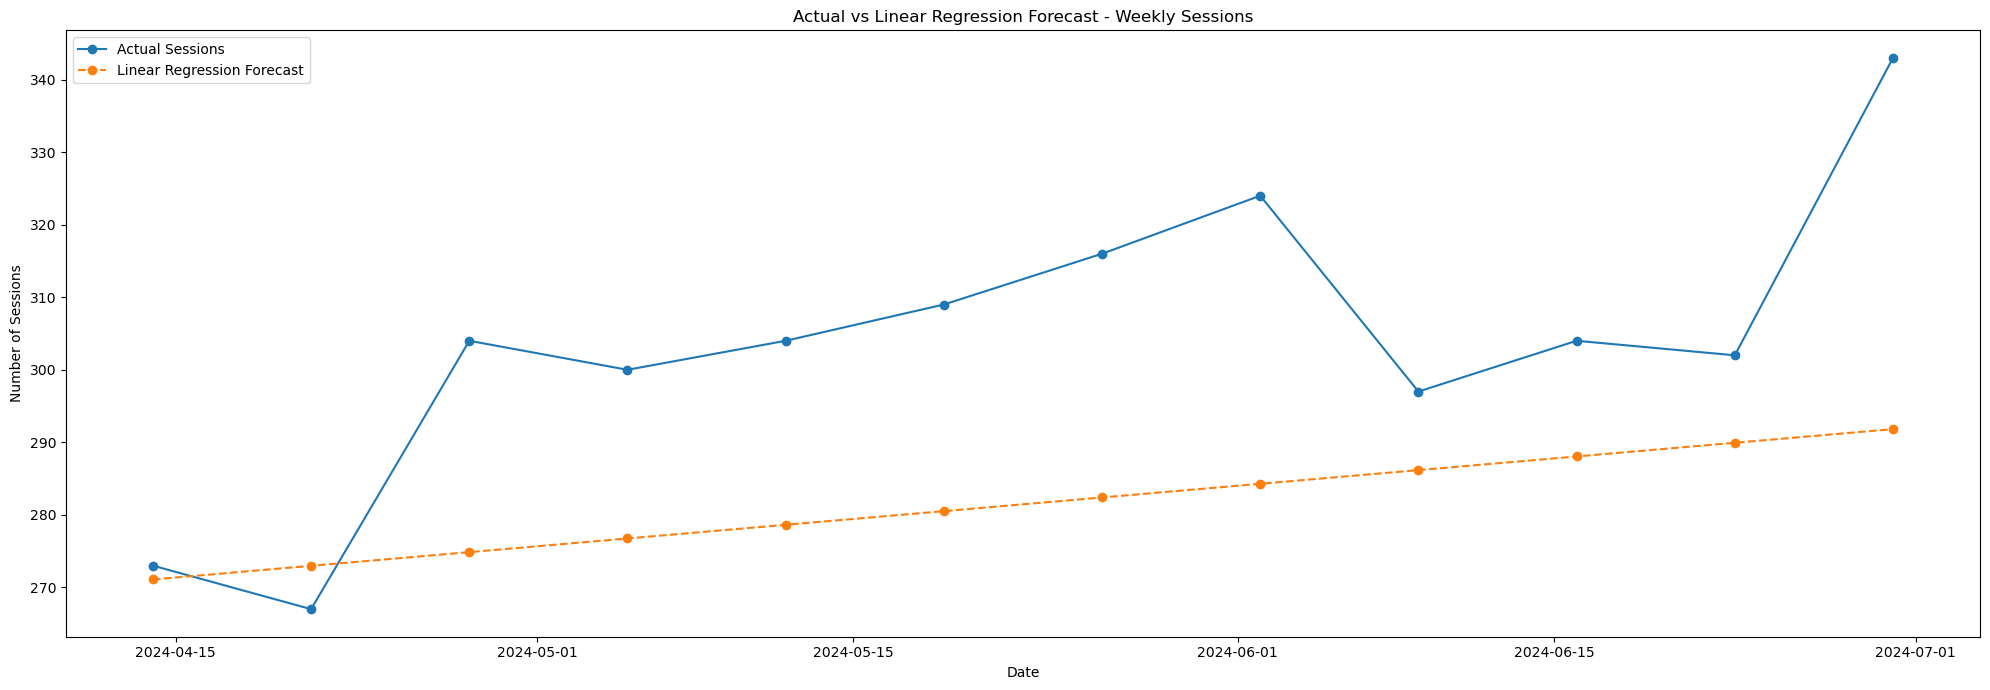

In [75]:
# Plot actual vs linear regression forecast
plt.figure()

plt.plot(
    test["session_start"],
    test["sessions"],
    marker="o",
    label="Actual Sessions"
)

plt.plot(
    test["session_start"],
    test["predicted_sessions_lr"],
    marker="o",
    linestyle="--",
    label="Linear Regression Forecast"
)

plt.title("Actual vs Linear Regression Forecast - Weekly Sessions")
plt.xlabel("Date")
plt.ylabel("Number of Sessions")
plt.legend()

plt.tight_layout()
plt.show()

In [76]:
# Calculate Linear Regression forecast errors

# MAE = average absolute error
lr_sessions_mae = mean_absolute_error(
    test["sessions"],
    test["predicted_sessions_lr"]
)

# RMSE = gives more weight to larger errors
lr_sessions_rmse = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["predicted_sessions_lr"]
    )
)

# Compare Linear Regression with the baseline
print(f"Baseline MAE: {sessions_mae:.2f}")
print(f"Linear Regression MAE: {lr_sessions_mae:.2f}")

print()

print(f"Baseline RMSE: {sessions_rmse:.2f}")
print(f"Linear Regression RMSE: {lr_sessions_rmse:.2f}")

Baseline MAE: 67.58
Linear Regression MAE: 23.12

Baseline RMSE: 70.30
Linear Regression RMSE: 26.97


In [77]:
# Select the target variable for weekly energy delivered
y_train_kwh = train["total_kwh"]
y_test_kwh = test["total_kwh"]

# Create the linear regression model
energy_model = LinearRegression()

# Train the model using week number and historical energy data
energy_model.fit(X_train, y_train_kwh)

# Predict energy delivered for the 12 test weeks
test["predicted_kwh_lr"] = energy_model.predict(X_test)

# Display actual and predicted energy values
test[
    [
        "session_start",
        "week_number",
        "total_kwh",
        "predicted_kwh_lr"
    ]
]

,session_start,week_number,total_kwh,predicted_kwh_lr
119,2024-04-14,119,4688.35360,4387.666606
120,2024-04-21,120,4258.09555,4420.045743
121,2024-04-28,121,4853.91863,4452.424880
122,2024-05-05,122,4864.70533,4484.804016
123,2024-05-12,123,4575.49177,4517.183153
124,2024-05-19,124,4968.69817,4549.562290
125,2024-05-26,125,5523.85585,4581.941427
126,2024-06-02,126,4413.76242,4614.320563
127,2024-06-09,127,4790.93346,4646.699700
128,2024-06-16,128,5164.13813,4679.078837


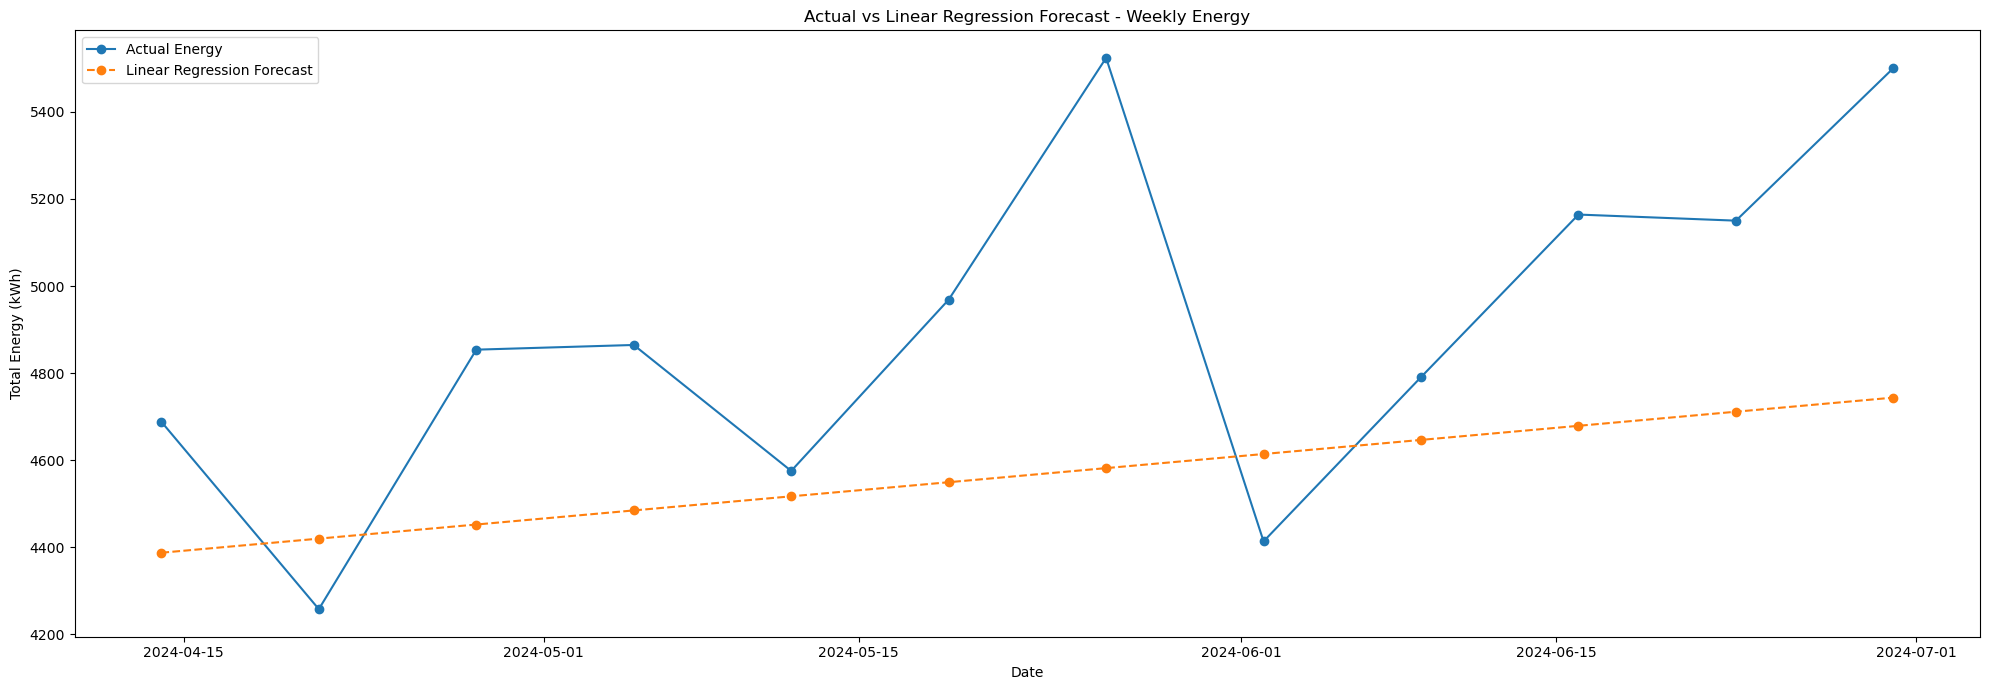

In [78]:
# Plot actual vs Linear Regression forecast for weekly energy
plt.figure()

plt.plot(
    test["session_start"],
    test["total_kwh"],
    marker="o",
    label="Actual Energy"
)

plt.plot(
    test["session_start"],
    test["predicted_kwh_lr"],
    marker="o",
    linestyle="--",
    label="Linear Regression Forecast"
)

plt.title("Actual vs Linear Regression Forecast - Weekly Energy")
plt.xlabel("Date")
plt.ylabel("Total Energy (kWh)")
plt.legend()

plt.tight_layout()
plt.show()

In [79]:
# Calculate Linear Regression forecast errors for weekly energy

# MAE = average absolute error
lr_kwh_mae = mean_absolute_error(
    test["total_kwh"],
    test["predicted_kwh_lr"]
)

# RMSE = gives more weight to larger forecast errors
lr_kwh_rmse = np.sqrt(
    mean_squared_error(
        test["total_kwh"],
        test["predicted_kwh_lr"]
    )
)

# Compare Linear Regression with the baseline
print(f"Baseline MAE: {kwh_mae:.2f} kWh")
print(f"Linear Regression MAE: {lr_kwh_mae:.2f} kWh")

print()

print(f"Baseline RMSE: {kwh_rmse:.2f} kWh")
print(f"Linear Regression RMSE: {lr_kwh_rmse:.2f} kWh")

Baseline MAE: 1097.91 kWh
Linear Regression MAE: 390.71 kWh

Baseline RMSE: 1160.65 kWh
Linear Regression RMSE: 460.94 kWh


In [80]:
# Compare the baseline and Linear Regression forecast errors
model_comparison = pd.DataFrame({
    "Target": [
        "Weekly Sessions",
        "Weekly Sessions",
        "Weekly Energy",
        "Weekly Energy"
    ],
    
    "Model": [
        "4-Week Baseline",
        "Linear Regression",
        "4-Week Baseline",
        "Linear Regression"
    ],
    
    "MAE": [
        sessions_mae,
        lr_sessions_mae,
        kwh_mae,
        lr_kwh_mae
    ],
    
    "RMSE": [
        sessions_rmse,
        lr_sessions_rmse,
        kwh_rmse,
        lr_kwh_rmse
    ]
})

model_comparison.round(2)

,Target,Model,MAE,RMSE
0,Weekly Sessions,4-Week Baseline,67.58,70.30
1,Weekly Sessions,Linear Regression,23.12,26.97
2,Weekly Energy,4-Week Baseline,1097.91,1160.65
3,Weekly Energy,Linear Regression,390.71,460.94


In [81]:
"""Using One week as basleine"""
# Create baseline forecasts using different recent-history windows

# 1-week baseline:
# Use the most recent training week as the forecast
baseline_1wk_sessions = train["sessions"].tail(1).mean()

# 2-week baseline:
# Use the average of the most recent 2 training weeks
baseline_2wk_sessions = train["sessions"].tail(2).mean()

# 4-week baseline:
# Use the average of the most recent 4 training weeks
baseline_4wk_sessions = train["sessions"].tail(4).mean()


# Add each baseline forecast to the test data
test["baseline_1wk"] = baseline_1wk_sessions
test["baseline_2wk"] = baseline_2wk_sessions
test["baseline_4wk"] = baseline_4wk_sessions

In [82]:
# Calculate MAE for each baseline
mae_1wk = mean_absolute_error(
    test["sessions"],
    test["baseline_1wk"]
)

mae_2wk = mean_absolute_error(
    test["sessions"],
    test["baseline_2wk"]
)

mae_4wk = mean_absolute_error(
    test["sessions"],
    test["baseline_4wk"]
)

# Calculate RMSE for each baseline
rmse_1wk = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["baseline_1wk"]
    )
)

rmse_2wk = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["baseline_2wk"]
    )
)

rmse_4wk = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["baseline_4wk"]
    )
)

print(f"1-Week Baseline MAE: {mae_1wk:.2f}")
print(f"2-Week Baseline MAE: {mae_2wk:.2f}")
print(f"4-Week Baseline MAE: {mae_4wk:.2f}")

print()

print(f"1-Week Baseline RMSE: {rmse_1wk:.2f}")
print(f"2-Week Baseline RMSE: {rmse_2wk:.2f}")
print(f"4-Week Baseline RMSE: {rmse_4wk:.2f}")

1-Week Baseline MAE: 79.58
2-Week Baseline MAE: 65.58
4-Week Baseline MAE: 67.58

1-Week Baseline RMSE: 81.90
2-Week Baseline RMSE: 68.37
4-Week Baseline RMSE: 70.30


### Baseline comparison

The **2-week baseline** performs best among the simple recent-history benchmarks:
- MAE: **65.58 sessions**
- RMSE: **68.37 sessions**

The 1-week baseline is more sensitive to weekly noise, while the 4-week baseline is slightly slower to react to the upward demand trend.


In [83]:
from statsmodels.tsa.arima.model import ARIMA

# Create the ARIMA model
# order=(1, 1, 1) means:
# p = 1 -> use 1 previous observation
# d = 1 -> difference the data once to help handle the upward trend
# q = 1 -> use 1 previous forecast error

arima_sessions_model = ARIMA(
    train["sessions"],
    order=(1, 1, 1)
)

# Train the ARIMA model using the historical training data
arima_sessions_fit = arima_sessions_model.fit()

# Forecast the next 12 weeks
arima_sessions_forecast = arima_sessions_fit.forecast(
    steps=len(test)
)

# Add the ARIMA predictions to the test dataframe
test["predicted_sessions_arima"] = arima_sessions_forecast.values

# Display actual and predicted values
test[
    [
        "session_start",
        "sessions",
        "predicted_sessions_lr",
        "predicted_sessions_arima"
    ]
]

,session_start,sessions,predicted_sessions_lr,predicted_sessions_arima
119,2024-04-14,273,271.093576,236.784094
120,2024-04-21,267,272.977909,236.350254
121,2024-04-28,304,274.862242,236.364976
122,2024-05-05,300,276.746575,236.364477
123,2024-05-12,304,278.630907,236.364494
124,2024-05-19,309,280.515240,236.364493
125,2024-05-26,316,282.399573,236.364493
126,2024-06-02,324,284.283905,236.364493
127,2024-06-09,297,286.168238,236.364493
128,2024-06-16,304,288.052571,236.364493


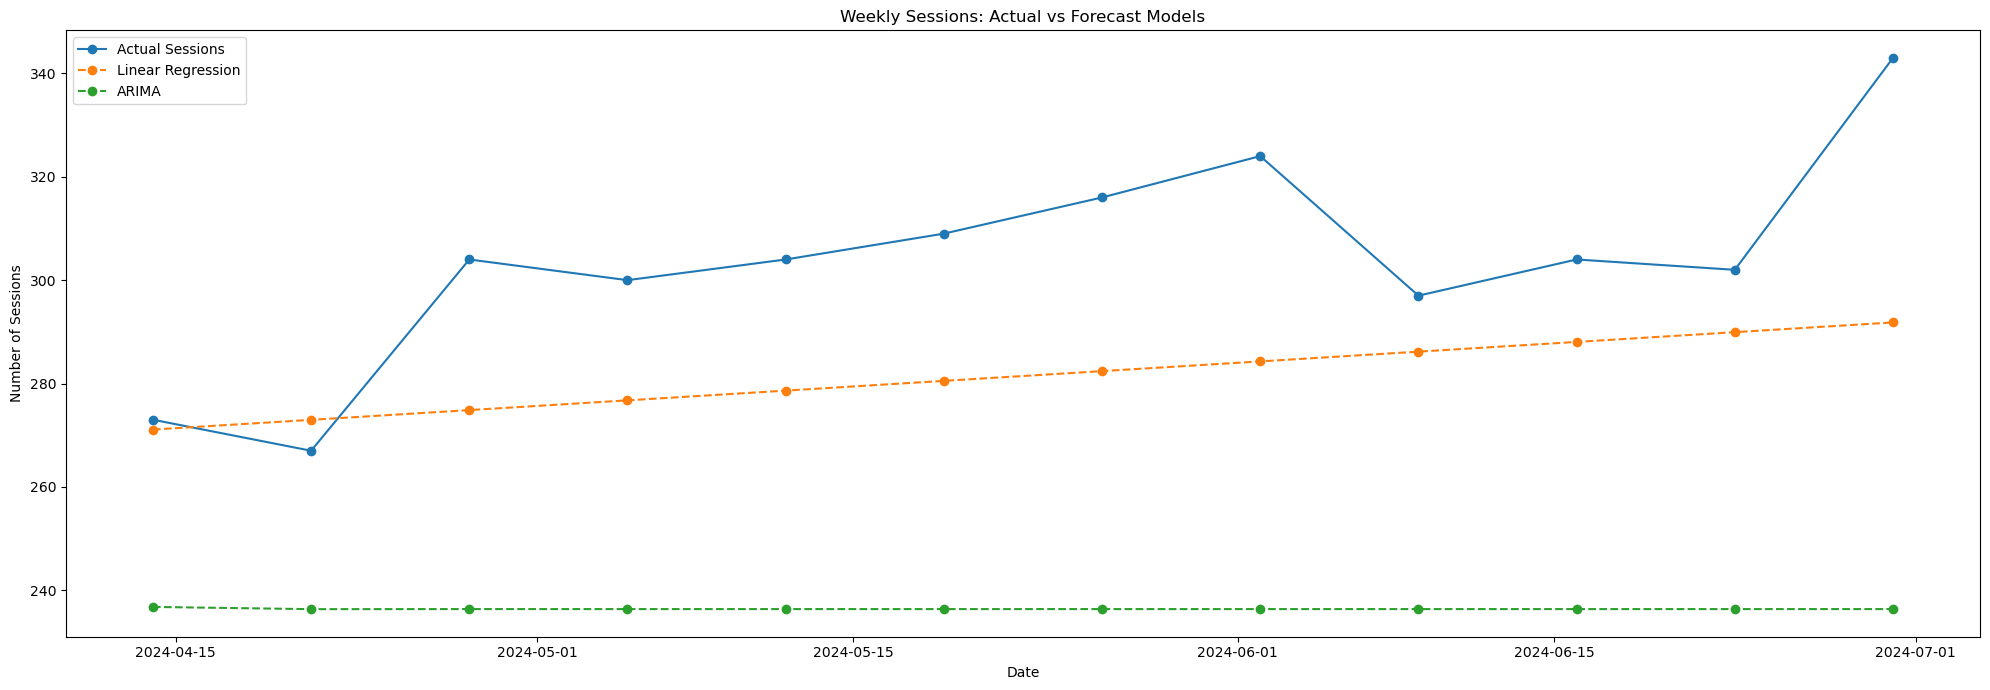

In [84]:
# Compare Actual, Linear Regression and ARIMA forecasts
plt.figure()

# Actual weekly sessions
plt.plot(
    test["session_start"],
    test["sessions"],
    marker="o",
    label="Actual Sessions"
)

# Linear Regression forecast
plt.plot(
    test["session_start"],
    test["predicted_sessions_lr"],
    linestyle="--",
    marker="o",
    label="Linear Regression"
)

# ARIMA forecast
plt.plot(
    test["session_start"],
    test["predicted_sessions_arima"],
    linestyle="--",
    marker="o",
    label="ARIMA"
)

plt.title("Weekly Sessions: Actual vs Forecast Models")
plt.xlabel("Date")
plt.ylabel("Number of Sessions")
plt.legend()

plt.tight_layout()
plt.show()

In [85]:
# Calculate ARIMA forecast errors

arima_sessions_mae = mean_absolute_error(
    test["sessions"],
    test["predicted_sessions_arima"]
)

arima_sessions_rmse = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["predicted_sessions_arima"]
    )
)

print(f"2-Week Baseline MAE: {mae_2wk:.2f}")
print(f"Linear Regression MAE: {lr_sessions_mae:.2f}")
print(f"ARIMA MAE: {arima_sessions_mae:.2f}")

print()

print(f"2-Week Baseline RMSE: {rmse_2wk:.2f}")
print(f"Linear Regression RMSE: {lr_sessions_rmse:.2f}")
print(f"ARIMA RMSE: {arima_sessions_rmse:.2f}")

2-Week Baseline MAE: 65.58
Linear Regression MAE: 23.12
ARIMA MAE: 67.19

2-Week Baseline RMSE: 68.37
Linear Regression RMSE: 26.97
ARIMA RMSE: 69.93


In [86]:
# Create an ARIMA model with a trend (drift)
# The trend allows the forecast to continue moving over time
# instead of settling into an almost flat forecast

arima_drift_model = ARIMA(
    train["sessions"],
    order=(1, 1, 1),
    trend="t"
)

# Train the model
arima_drift_fit = arima_drift_model.fit()

# Forecast the 12 test weeks
test["predicted_sessions_arima_drift"] = (
    arima_drift_fit.forecast(steps=len(test)).values
)

# Display actual and predicted values
test[
    [
        "session_start",
        "sessions",
        "predicted_sessions_lr",
        "predicted_sessions_arima",
        "predicted_sessions_arima_drift"
    ]
]

,session_start,sessions,predicted_sessions_lr,predicted_sessions_arima,predicted_sessions_arima_drift
119,2024-04-14,273,271.093576,236.784094,241.738579
120,2024-04-21,267,272.977909,236.350254,243.875006
121,2024-04-28,304,274.862242,236.364976,245.839516
122,2024-05-05,300,276.746575,236.364477,247.802131
123,2024-05-12,304,278.630907,236.364494,249.764726
124,2024-05-19,309,280.515240,236.364493,251.727321
125,2024-05-26,316,282.399573,236.364493,253.689916
126,2024-06-02,324,284.283905,236.364493,255.652510
127,2024-06-09,297,286.168238,236.364493,257.615105
128,2024-06-16,304,288.052571,236.364493,259.577700


In [87]:
# Calculate ARIMA with drift forecast errors
arima_drift_mae = mean_absolute_error(
    test["sessions"],
    test["predicted_sessions_arima_drift"]
)

arima_drift_rmse = np.sqrt(
    mean_squared_error(
        test["sessions"],
        test["predicted_sessions_arima_drift"]
    )
)

# Compare all models
print(f"2-Week Baseline MAE: {mae_2wk:.2f}")
print(f"Linear Regression MAE: {lr_sessions_mae:.2f}")
print(f"ARIMA MAE: {arima_sessions_mae:.2f}")
print(f"ARIMA with Drift MAE: {arima_drift_mae:.2f}")

print()

print(f"2-Week Baseline RMSE: {rmse_2wk:.2f}")
print(f"Linear Regression RMSE: {lr_sessions_rmse:.2f}")
print(f"ARIMA RMSE: {arima_sessions_rmse:.2f}")
print(f"ARIMA with Drift RMSE: {arima_drift_rmse:.2f}")

2-Week Baseline MAE: 65.58
Linear Regression MAE: 23.12
ARIMA MAE: 67.19
ARIMA with Drift MAE: 50.89

2-Week Baseline RMSE: 68.37
Linear Regression RMSE: 26.97
ARIMA RMSE: 69.93
ARIMA with Drift RMSE: 53.13


## Q5 Conclusion

Historical charging demand contains useful predictive information.

For weekly sessions:
- 2-week baseline: MAE **65.58**, RMSE **68.37**
- Linear Regression: MAE **23.12**, RMSE **26.97**
- ARIMA(1,1,1): MAE **67.19**, RMSE **69.93**
- ARIMA(1,1,1) with drift: MAE **50.89**, RMSE **53.13**

Linear Regression performs best among the models tested. Its advantage comes from capturing the strong upward time trend in charging demand.

For weekly energy, Linear Regression also substantially improves on the simple baseline:
- baseline MAE: **1,097.91 kWh**
- Linear Regression MAE: **390.71 kWh**

ARIMA with drift improves materially over plain ARIMA but still does not outperform Linear Regression.

An LSTM was not pursued because the weekly series provides only 119 training observations after the chronological split, which is limited for a neural-network model.

The remaining week-to-week forecast error may reflect seasonality, weather, holidays, major Ottawa events, or other external factors that are not included in the simple time-trend model.


---

# Optional Extension: Estimated Charging Revenue

If time permits, charging revenue can be estimated using historical City of Ottawa charging rates.

Any financial results should be labelled **estimated revenue**, because the dataset records energy usage rather than actual billed amounts and may not capture parking fees, taxes, discounts, failed payments, or changes in pricing policy.

Where historical rates changed over time, the applicable rate should be matched to the corresponding charging period rather than applying one current rate to the entire dataset.


In [88]:
# Official tariff and utility benchmarks

# Park & Ride charging fee
park_and_ride_fee = 3.50

# Standard municipal Level 2 charging fee
standard_hourly_rate = 2.00

# Estimated electricity cost paid to the utility
electricity_cost_per_kwh = 0.12

### Financial assumptions

The charging-fee assumptions are based on published City of Ottawa pricing:

- Park & Ride chargers: **$3.50 per session**
- Other municipal Level 2 chargers: **$2.00 per hour**

The **$0.12/kWh electricity-cost value is a simplified analytical benchmark**, not a verified all-in Hydro Ottawa cost paid by the City. Actual electricity expense can vary with rate class, time-of-use period, delivery charges, demand charges, and other billing components.


In [89]:
# Estimate charging revenue for each session

# Standard municipal chargers:
# Revenue is based on session duration at $2.00 per hour
df["estimated_revenue"] = (
    df["duration_hours"] * standard_hourly_rate
)

# Chapel Hill Park & Ride:
# Replace the hourly calculation with the $3.50 flat session fee
df.loc[
    df["site"].str.contains(
        "Chapel Hill",
        case=False,
        na=False
    ),
    "estimated_revenue"
] = park_and_ride_fee

In [90]:
# Estimate electricity cost for each charging session
df["estimated_electricity_cost"] = (
    df["total_kwh"] * electricity_cost_per_kwh
)

In [91]:
# Estimate gross charging margin
# This is charging revenue minus estimated electricity cost
df["estimated_gross_margin"] = (
    df["estimated_revenue"]
    - df["estimated_electricity_cost"]
)

In [92]:
# Calculate overall financial estimates
total_revenue = df["estimated_revenue"].sum()
total_electricity_cost = df["estimated_electricity_cost"].sum()
total_gross_margin = df["estimated_gross_margin"].sum()

print(f"Estimated Charging Revenue: ${total_revenue:,.2f}")
print(f"Estimated Electricity Cost: ${total_electricity_cost:,.2f}")
print(f"Estimated Gross Margin: ${total_gross_margin:,.2f}")

Estimated Charging Revenue: $120,395.59
Estimated Electricity Cost: $41,963.74
Estimated Gross Margin: $78,431.85


In [93]:
# Summarize estimated financial performance by site
site_financials = (
    df.groupby("site")
    .agg(
        sessions=("session_id", "count"),
        total_kwh=("total_kwh", "sum"),
        total_hours=("duration_hours", "sum"),
        estimated_revenue=("estimated_revenue", "sum"),
        estimated_electricity_cost=("estimated_electricity_cost", "sum"),
        estimated_gross_margin=("estimated_gross_margin", "sum")
    )
    .reset_index()
)

# Sort sites from highest to lowest estimated revenue
site_financials = site_financials.sort_values(
    "estimated_revenue",
    ascending=False
)

site_financials

,site,sessions,total_kwh,total_hours,estimated_revenue,estimated_electricity_cost,estimated_gross_margin
2,City of Ottawa - 118 Cartier St.,2546,40702.58792,7282.012222,14564.024444,4884.310550,9679.713894
3,City of Ottawa - 122 Daly Ave.,1868,34562.97277,6412.614444,12825.228889,4147.556732,8677.672156
11,City of Ottawa - 301 Laurier Avenue,2068,32687.79148,6163.583611,12327.167222,3922.534978,8404.632245
16,City of Ottawa - 930 Wellington Street,1479,28968.38482,5197.642778,10395.285556,3476.206178,6919.079377
0,City Hall - Ottawa,2507,25228.29039,4651.755000,9303.510000,3027.394847,6276.115153
15,City of Ottawa - 6 Oak St.,1573,26014.46440,4446.156667,8892.313333,3121.735728,5770.577605
7,City of Ottawa - 190 Richmond Road,1511,21496.55318,3669.779444,7339.558889,2579.586382,4759.972507
6,City of Ottawa - 186 Main St.,1546,21281.65754,3643.029444,7286.058889,2553.798905,4732.259984
8,City of Ottawa - 245 Crichton St.,1165,18425.61202,3282.871667,6565.743333,2211.073442,4354.669891
5,City of Ottawa - 170 Primrose Ave.,935,17743.25135,3035.558611,6071.117222,2129.190162,3941.927060


## Estimated Revenue Interpretation

Using the stated assumptions, the analysis estimates:

- charging revenue: about **$120,396**
- electricity cost: about **$41,964**
- gross charging margin: about **$78,432**

These values are **not audited City revenue or profit**.

`estimated_gross_margin` subtracts only the assumed electricity cost. It does not include installation, maintenance, networking/software fees, payment processing, repairs, administration, taxes, depreciation, or other operating costs.

The separate infrastructure notebook may later improve this section by providing site-specific tariff information. A future version could therefore be described as **tariff-informed estimated charging revenue** rather than applying broad charging-rate assumptions.
